# 🔎📚 Lab 04: RAG Evaluation Pipeline

## Module 04: Evaluating Retrieval-Augmented Systems 📚

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/04-rag-evaluation-lab.ipynb)

<center><font size="6"><b>Every answer sounds right. Would you ship it?</b></font></center>

An HR policy assistant. One answer will <mark>pass every check you build and still be wrong</mark>. ⏱️ Part 1: ~25 min.

<!-- img: comic-never-says-idk.png -->
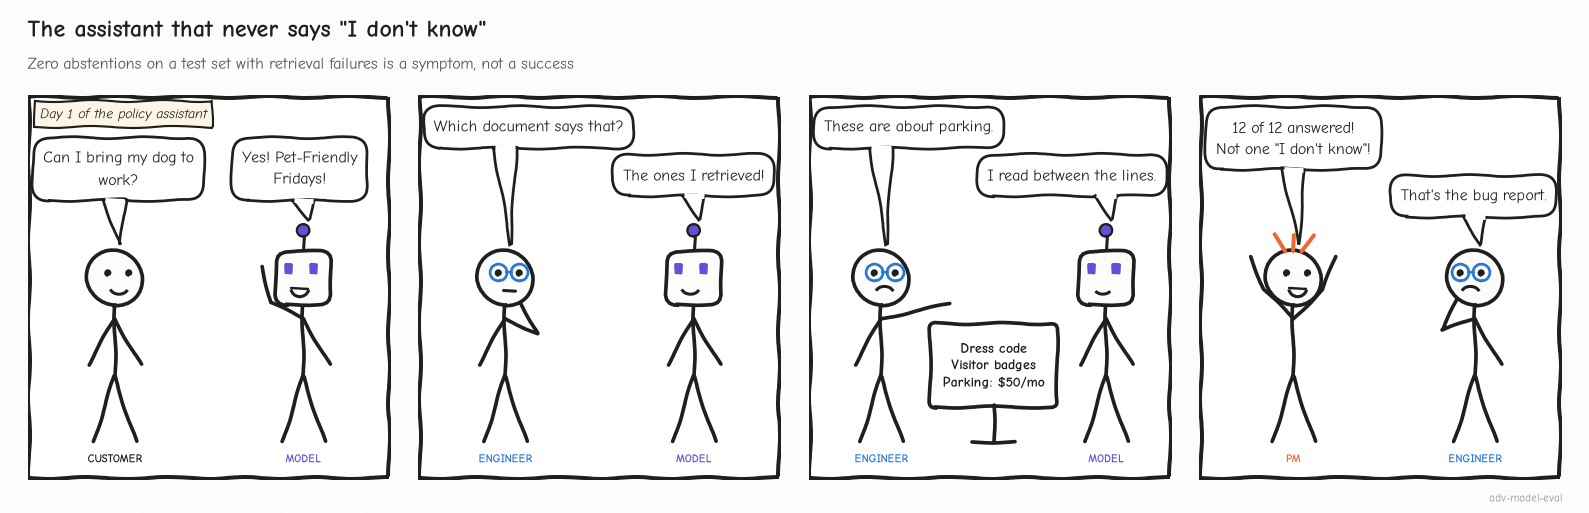

| | |
|---|---|
| ⏱️ **Time** | 40–45 min hands-on (Tasks 10–11 can shrink to 5 min each) |
| 🎚️ **Level** | Intermediate |
| 🔑 **Keys needed** | None. Runs offline after a one-time ~90 MB NLI model download |
| 🧰 **Tools** | `sentence-transformers` (NLI cross-encoder) · `pandas` · `numpy` · `matplotlib` |
| ✍️ **You'll write** | Grounding criteria (Task 5), stress tests (Task 10), failure analysis (Task 11) |
| 🏁 **You'll leave with** | Retrieval, faithfulness and **context-sufficiency** scores, a selective-answer metric (coverage vs. accuracy), a root cause for every query, and a ship/block verdict |
| ➡️ **Next** | Lab 04b builds a *real* RAG pipeline (chunking, hybrid search, reranking) and evaluates it |

**How this lab works**
- ▶️ **Run**: <kbd>Shift</kbd>+<kbd>Enter</kbd>; collapsed 🧰 cells just need running.
- ✋ **Your turn**: replace the `...`; a card grades it.
- ❓ **Quick check**: pick an answer, then run.
- 🔑 **Key takeaway**: the line to remember.

<!-- img: rag-eval-map.png -->
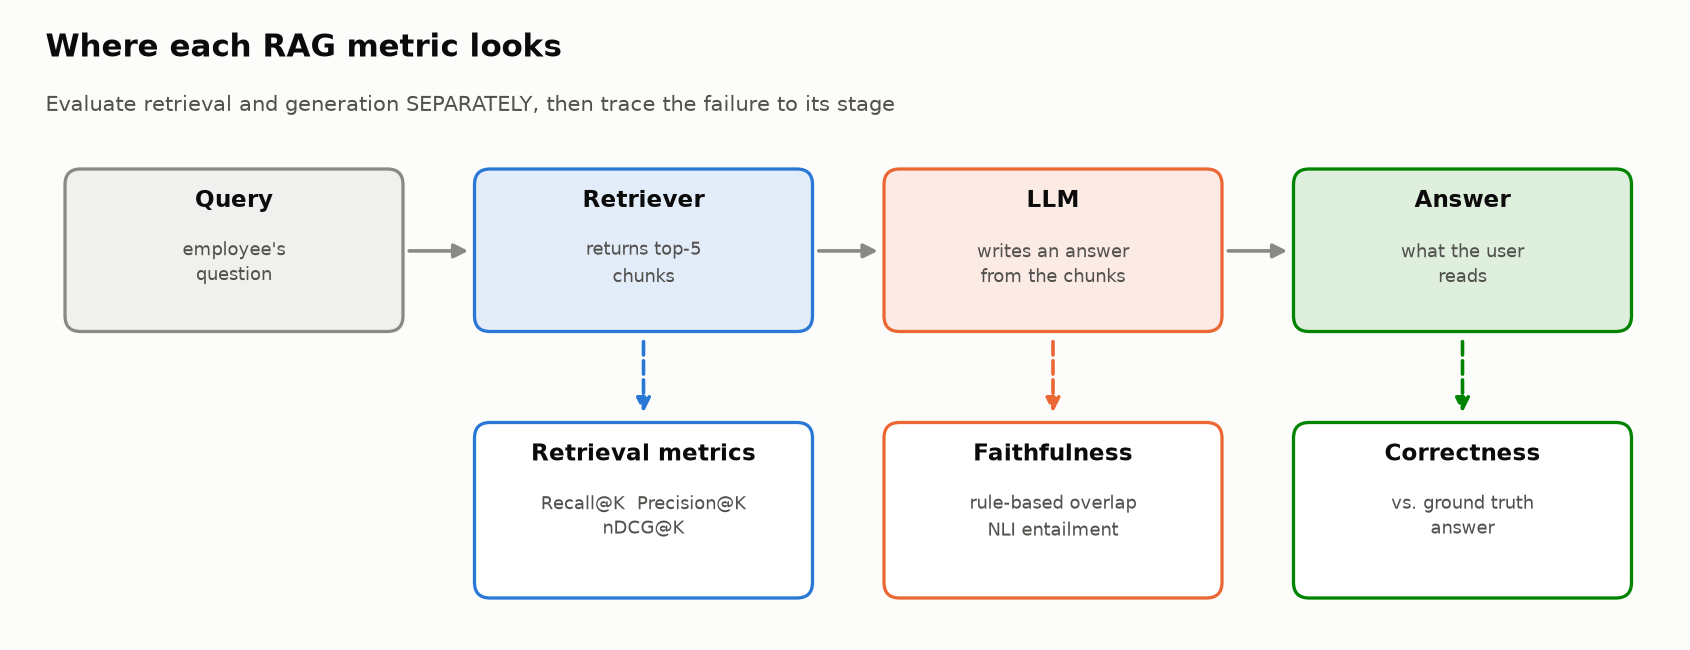

<details>
<summary>🗺️ What each stage is measured by · the roadmap</summary>

**RAG:** a **retriever** fetches K passages, a **generator** (an LLM) writes from them. Either can fail, and so can the decision to answer.

| Question | Stage | Measured by |
|---|---|---|
| Did we fetch the right documents? | Retrieval | Recall@K, Precision@K, nDCG, MRR (Task 4) |
| Does the answer stick to what was fetched? | Generation | **Faithfulness** (Tasks 5–6) |
| Is the answer true? | End to end | **Correctness** against the current handbook (Task 8) |
| Could *anyone* answer from this context, and should the system have declined? | Both | **Context sufficiency** and abstention (Task 9) |

<!-- img: lab-roadmap.png -->
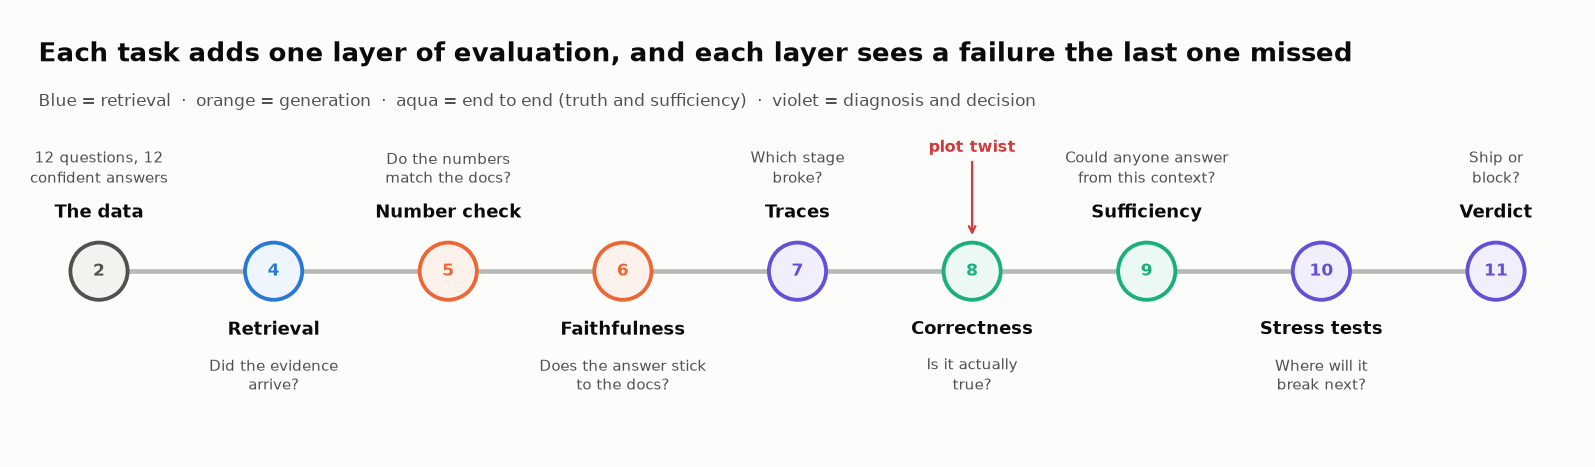

</details>

<details>
<summary>📖 <b>Jargon decoder: 35 terms this lab uses (click to open)</b></summary>

| Term | Plain-English meaning | Where you'll meet it |
|---|---|---|
| **RAG** (retrieval-augmented generation) | Look up passages first, then have an LLM write the answer from them | Everywhere |
| **Retriever / generator** | The search step that picks passages / the LLM that writes from them | Overview, Task 7 |
| **Chunk** (here: doc) | A passage cut from a document and stored for search; each doc here is one short policy | Task 2 |
| **Corpus / index** | Every document you *could* retrieve / the searchable store built from it | Tasks 4, 8 |
| **Top-K** | The K highest-scoring chunks handed to the LLM (K = 5 here) | Task 4 |
| **Relevance label** | A person's 1/0 call: is this doc on-topic for the question? On-topic ≠ contains the answer | Tasks 2, 4, 9 |
| **Recall@K / hit rate** | Share of the relevant docs that made the top K / share of queries with at least one | Task 4 |
| **Precision@K** | Share of the top K that are relevant (how much noise came along) | Task 4 |
| **nDCG@K** | A 0–1 ranking score that gives more credit for relevant docs near the top | Task 4 |
| **MRR** (mean reciprocal rank) | Average of 1 ÷ (rank of the first relevant doc) | Task 4 |
| **Grounding / faithfulness** | Every claim in the answer is supported by the retrieved docs (not "is true") | Tasks 5–6 |
| **Distortion / fabrication / hallucination** | A changed fact / a claim with no source at all / the umbrella term for confident unsupported output | Tasks 5, 7 |
| **Stop words** | Very common words a word-counting scorer throws away before comparing texts | Task 6 |
| **Claim / claim-level scoring** | One checkable statement in an answer (here, one sentence) / scoring each claim on its own, then keeping the weakest | Task 6, Challenge 5 |
| **NLI** (natural language inference) | A model that reads a **premise** and a **hypothesis** and says *entailment* (supports), *contradiction* or *neutral* | Task 6 |
| **Cross-encoder vs. embedding** | Reads both texts together in one pass / turns each text into a vector separately and compares the vectors | Task 6 |
| **Logits / softmax** | A model's raw scores / the step that turns them into probabilities summing to 1 | Task 6 |
| **Miss rate / false-alarm rate** | Bad answers a scorer passes / good answers it flags | Task 6 |
| **TPR / TNR** | True-positive rate (1 − miss rate) / true-negative rate (1 − false-alarm rate) | Tasks 6, 9 |
| **Trace / span** | The record of one request through the pipeline / one step inside it | Task 7 |
| **OpenTelemetry (OTel)** | The open standard for recording traces; its GenAI conventions name LLM spans | Task 7 |
| **Root cause** | The earliest pipeline stage that went wrong | Task 7 |
| **Ground truth / correctness** | The trusted right answer (here: the current handbook) / whether the answer matches it | Task 8 |
| **SME** | Subject-matter expert; here a benefits specialist who grades answers | Task 8 |
| **Doc-derived (synthetic) set vs. production sample** | Questions written while reading the docs / questions real users typed | Task 8 |
| **95% CI / Wilson interval** | The range of true rates consistent with your score / a CI formula that behaves at small n | Task 8 |
| **Index hygiene / freshness metadata** | Removing outdated versions from search / tagging each chunk with its effective date | Tasks 8, 11 |
| **Abstention / over-refusal** | Declining to answer / declining when the answer *was* in the docs | Tasks 2, 9 |
| **Context sufficiency / key facts** | Whether the retrieved text contains everything needed to answer / the facts an answer must include | Task 9 |
| **Coverage / selective accuracy** | Share of questions answered / share of *answered* questions that are correct | Task 9 |
| **Autorater (LLM judge)** | An LLM prompted to grade something, here sufficiency | Task 9 |
| **Stress test / probe** | A question written to make the system fail in a specific way | Task 10 |
| **CI pipeline** (continuous integration) | The automated tests that run on every change; not the confidence interval | Task 11 |
| **PTO · stipend · per diem** | Paid time off · a fixed allowance for a purpose · a fixed daily travel allowance | Queries 1, 9, 13, 15 |
| **401(k) · match · vesting · stock options** | US workplace retirement account · employer money added when you contribute · employer money becoming yours over time · the right to buy shares at a set price, which vest, can be *exercised* (bought), or are *forfeited* | Queries 5, 12, 14 |

</details>

<details>
<summary>🎯 Objectives · prerequisites · setup · scenario</summary>

## 🎯 Learning Objectives

Pick a retrieval headline metric; score faithfulness two ways and measure each scorer's errors; show faithful ≠ correct; score sufficiency and abstention both ways; make a ship call.

## 📋 Prerequisites

Modules 01–02; the query → retrieval → generation flow; pandas.

## ⏱️ Estimated Time

Part 1 ~25 min · Part 2 ~20 min · challenges +45 min.

## ⚙️ Environment and Setup

Colab, CPU, no API keys: every answer is pre-generated.

## 🎬 Scenario

You sign off on the assistant's company-wide rollout.
</details>

---

🧭 **Where you are:** Act I of IV (Tasks 1–3): the case.

## 🛠️ Task 1: Environment Setup and Dependencies

<big><b>Fixed answers, so your numbers match every checkpoint.</b></big>

> 🎯 **Goal:** install, import, load the lab kit.<br>
> ❓ **The question:** what does a frozen test set buy you?<br>
> 👀 **Watch for:** `✅ All imports successful.`

▶️ **Run** the next three cells: 📦 install (1–2 min the first time) · imports · 🎨 lab kit (collapsed).

In [ ]:
%%capture
# Install required packages:
#   sentence-transformers → the NLI cross-encoder for faithfulness scoring (Task 6)
#   pandas / numpy        → tables and numerical operations
#   matplotlib            → one chart per task
!pip install -q sentence-transformers pandas numpy matplotlib

In [ ]:
# Core libraries for data handling and analysis
import re                         # tokenizing answers and extracting numbers
import math                       # Wilson confidence intervals (Task 8)
import json                       # JSON handling (if loading external datasets)
from collections import defaultdict, Counter

import numpy as np                # nDCG log calculations
import pandas as pd               # tables of per-query metrics
import matplotlib.pyplot as plt   # charts

pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 60)
plt.rcParams["axes.axisbelow"] = True   # draw gridlines behind bars
print("✅ All imports successful.")

In [ ]:
# @title 🎨 Lab kit: insight cards, stat tiles, chart theme (run me; no need to read)
# LABKIT v2 — shared across every lab in this course. Pure Python + IPython; no installs.
# Functions you'll see used in this notebook:
#   insight(headline, body, kind="insight")   -> a callout card that states what the numbers just revealed
#   tiles([(label, value, note, status), ...])  -> a row of KPI tiles (status: good|warning|serious|critical|None)
#   verdict(decision, reasons)                  -> a SHIP / SHIP WITH CAUTION / BLOCK banner
#   style_charts()                              -> one consistent matplotlib theme (called automatically)
#   PALETTE / STATUS                            -> the colors used in every chart
#   check(label, got, expected, hint=, success=) -> grades a ✋ Your turn exercise: ✅ / ❌ + hint / ⏳ (still `...`)
#   quiz(label, choice, correct, why, wrong=)    -> grades a ❓ dropdown answer and explains it
#   todo(x)                                      -> True while an exercise blank is still `...`
#   scoreboard()                                 -> your exercise + quiz score so far, and what to revisit
import html as _html

try:
    from IPython.display import HTML as _HTML, display as _display
except ImportError:  # running as a plain script
    _HTML, _display = None, None

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STATUS = {"good": "#0ca30c", "warning": "#fab219", "serious": "#ec835a", "critical": "#d03b3b"}
_STATUS_ICON = {"good": "✅", "warning": "⚠️", "serious": "🟠", "critical": "⛔"}

_KINDS = {
    #  kind        icon  label                    accent     tint
    "insight":    ("💡", "Insight",               "#2a78d6", "#eef5fd"),
    "surprise":   ("🤯", "Counterintuitive",      "#6250d6", "#f1effc"),
    "warning":    ("⚠️", "Watch out",             "#ec835a", "#fdf1ec"),
    "production": ("🏭", "In production",         "#1baf7a", "#ebf8f3"),
    "numbers":    ("📈", "By the numbers",        "#eda100", "#fdf6e6"),
    "research":   ("📚", "What the research says", "#52514e", "#f3f2ef"),
}


def _show(markup):
    if _display is not None:
        _display(_HTML(markup))
    else:
        import re
        print(re.sub(r"<[^>]+>", "", markup))


def _md(text):
    """Tiny formatter: **bold**, `code`, and newlines. Everything else is escaped."""
    import re
    t = _html.escape(str(text))
    t = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", t)
    t = re.sub(r"(?<![\w*])\*(?!\s)(.+?)(?<!\s)\*(?![\w*])", r"<i>\1</i>", t)
    t = re.sub(r"`(.+?)`", r"<code style='background:#0000000d;padding:1px 4px;border-radius:4px'>\1</code>", t)
    return t.replace("\n", "<br>")


def insight(headline, body="", kind="insight"):
    """Render a callout card. Use it right after a result to say what the result *means*."""
    icon, label, accent, tint = _KINDS.get(kind, _KINDS["insight"])
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:12px 16px;margin:10px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {label}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:4px 0 6px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def tiles(items):
    """items: list of (label, value, note, status). status in good|warning|serious|critical|None."""
    cells = []
    for item in items:
        label, value, note, status = (list(item) + [None, None, None, None])[:4]
        color = STATUS.get(status, "#d9d8d4")
        icon = _STATUS_ICON.get(status, "")
        cells.append(
            f"<div style='flex:1 1 160px;min-width:150px;background:#fcfcfb;border:1px solid #e4e3df;"
            f"border-top:4px solid {color};border-radius:8px;padding:10px 14px'>"
            f"<div style='font-size:12px;color:#52514e'>{_md(label)}</div>"
            f"<div style='font-size:26px;font-weight:700;color:#0b0b0b;margin:2px 0'>{_md(value)}</div>"
            f"<div style='font-size:12px;color:#52514e'>{icon} {_md(note or '')}</div></div>"
        )
    _show(
        "<div style='display:flex;flex-wrap:wrap;gap:10px;margin:10px 0;"
        "font-family:system-ui,-apple-system,sans-serif;max-width:900px'>" + "".join(cells) + "</div>"
    )


def verdict(decision, reasons=()):
    """decision: 'SHIP' | 'SHIP WITH CAUTION' | 'BLOCK' (anything else renders neutral)."""
    d = str(decision).upper()
    status = "good" if d == "SHIP" else "critical" if d.startswith("BLOCK") else "warning"
    icon = {"good": "🚀", "critical": "🛑", "warning": "⚠️"}[status]
    items = "".join(f"<li>{_md(r)}</li>" for r in reasons)
    _show(
        f"<div style='border:2px solid {STATUS[status]};border-radius:10px;padding:12px 18px;margin:10px 0;"
        f"background:#fcfcfb;color:#0b0b0b;font-family:system-ui,-apple-system,sans-serif;max-width:900px'>"
        f"<div style='font-size:22px;font-weight:800'>{icon} {_html.escape(d)}</div>"
        f"<ul style='margin:6px 0 0 18px;padding:0;font-size:14px;line-height:1.5'>{items}</ul></div>"
    )


def style_charts():
    """One chart theme for the whole course: thin marks, recessive grid, fixed color order."""
    try:
        import matplotlib as mpl
        from cycler import cycler
    except ImportError:
        return
    mpl.rcParams.update({
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
        "axes.edgecolor": "#b9b8b3", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
        "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e9e8e4", "grid.linewidth": 0.8,
        "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 11,
        "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
        "axes.prop_cycle": cycler(color=PALETTE), "figure.dpi": 110,
    })


# ----------------------------------------------------------------- interactive: exercises, quizzes, score
_SCORE = {}   # label -> (kind, status) where status is "pass" | "fail" | "todo"


class _Graded(int):
    """check()/quiz() result: works like True/False (if, ==, sum) but prints nothing as a cell's last line."""
    def __repr__(self):
        return "True" if self else "False"

    def _ipython_display_(self):
        pass


def todo(x):
    """True while an exercise blank is still `...` (or None)."""
    return x is Ellipsis or x is None


def _card(icon, label, headline, body, accent, tint):
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:10px 16px;margin:8px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {_md(label)}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:3px 0 4px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def _same(got, expected, tol):
    try:
        import numpy as _np
        if isinstance(got, (_np.generic,)):
            got = got.item()
        if isinstance(expected, (_np.generic,)):
            expected = expected.item()
    except ImportError:
        pass
    if isinstance(expected, bool) or isinstance(got, bool):
        return got == expected
    if isinstance(expected, (int, float)) and isinstance(got, (int, float)):
        return abs(float(got) - float(expected)) <= tol * max(1.0, abs(float(expected)))
    if isinstance(expected, str) and isinstance(got, str):
        return got.strip().lower() == expected.strip().lower()
    if isinstance(expected, (set, frozenset)) or isinstance(got, (set, frozenset)):
        try:
            return set(got) == set(expected)
        except TypeError:
            return False
    return got == expected


def check(label, got, expected=None, *, ok=None, tol=1e-6, hint="", success="", reveal=False):
    """Grade a ✋ Your turn exercise.

    got:      the learner's answer (still `...` = not attempted yet: shows ⏳, never an error)
    expected: the reference answer (compared with tolerance for numbers, case-insensitively for strings)
    ok:       pass a bool instead of `expected` for custom rules (e.g. ok=my_case_fools_the_grader)
    reveal:   show the expected answer on a wrong attempt (default False: the hint teaches, the answer spoils)
    """
    if todo(got):
        _SCORE[label] = ("exercise", "todo")
        _card("⏳", f"Your turn · {label}", "Not attempted yet",
              "Replace the `...` above with your answer and re-run this cell. "
              "The lab keeps going with the reference answer, so later cells still work.", "#9a9893", "#f3f2ef")
        return _Graded(False)
    try:
        passed = bool(ok) if ok is not None else _same(got, expected, tol)
    except Exception:
        passed = False
    _SCORE[label] = ("exercise", "pass" if passed else "fail")
    if passed:
        _card("✅", f"Correct · {label}", success or "Nice. That matches the reference.", "", "#0ca30c", "#ecf8ec")
    else:
        shown = f"You got `{got!r}`" + (f"; expected `{expected!r}`" if reveal and ok is None and expected is not None else "") + "."
        _card("❌", f"Not yet · {label}", shown, (f"💡 Hint: {hint}" if hint else "Re-read the step above and try again."),
              "#d03b3b", "#fcefef")
    return _Graded(passed)


def quiz(label, choice, correct, why, wrong=None):
    """Grade a ❓ dropdown answer. choice: the @param string, e.g. "B) The average hides it".
    correct: the letter ("B"). why: the explanation (shown once answered). wrong: {letter: feedback for that pick}."""
    pick = str(choice).strip()[:1].upper()
    if not pick.isalpha():
        _SCORE[label] = ("quiz", "todo")
        _card("❓", f"Quick check · {label}", "Pick an answer in the dropdown, then run this cell.",
              "Commit before you scroll: a guess you wrote down is what makes the next result stick.", "#9a9893", "#f3f2ef")
        return _Graded(False)
    passed = pick == str(correct).strip()[:1].upper()
    _SCORE[label] = ("quiz", "pass" if passed else "fail")
    extra = (wrong or {}).get(pick, "")
    if passed:
        _card("✅", f"Quick check · {label}", f"Right: {correct}.", why, "#0ca30c", "#ecf8ec")
    else:
        _card("🔁", f"Quick check · {label}", f"Not quite: you picked {pick}, the answer is {correct}.",
              (extra + "\n" if extra else "") + why, "#ec835a", "#fdf1ec")
    return _Graded(passed)


def scoreboard():
    """Your score on every ✋ exercise and ❓ quick check you've run, plus what to revisit."""
    ex = [s for k, s in _SCORE.values() if k == "exercise"]
    qz = [s for k, s in _SCORE.values() if k == "quiz"]
    redo = [lbl for lbl, (_, s) in _SCORE.items() if s != "pass"]
    tiles([
        ("✋ Exercises solved", f"{ex.count('pass')}/{len(ex)}", f"{ex.count('todo')} not attempted",
         "good" if ex and ex.count("pass") == len(ex) else "warning"),
        ("❓ Quick checks right", f"{qz.count('pass')}/{len(qz)}", f"{qz.count('todo')} unanswered",
         "good" if qz and qz.count("pass") == len(qz) else "warning"),
    ])
    if redo:
        insight("Worth a second pass", "\n".join(f"• {r}" for r in redo), kind="warning")
    elif _SCORE:
        insight("Clean sweep", "Every exercise and quick check correct. Try the 🏆 challenges next.", kind="insight")


style_charts()
print("🎨 Lab kit loaded: insight(), tiles(), verdict(), check(), quiz(), scoreboard()")

✋ **Your turn (warm-up):** run the collapsed answer key, then fill the blank below it.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_noise = (5 - 1) / 5

In [ ]:
# ✋ Your turn (warm-up): Query 1 retrieves K = 5 chunks. One is about PTO and holds the whole answer.
#    What share of what the LLM reads is off-topic?
k, n_relevant = 5, 1

my_noise_share = ...   # ✏️ one expression using k and n_relevant

check("Warm-up: how much of the context is noise?", my_noise_share, _ref_noise,
      hint="Off-topic chunks are the ones that aren't relevant. Count them, then divide by everything retrieved.",
      success=f"{_ref_noise:.0%} noise, and Query 1's answer is still perfect. Precision@5 (Task 4) measures that noise, not failure.")

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** `✅ All imports successful.` · `🎨 Lab kit loaded…`. `ModuleNotFoundError`: re-run the install, restart.
</details>

In [ ]:
# @title ❓ Quick check: every answer here is pre-generated. What does that buy you?
answer = "— pick one —"  # @param ["— pick one —", "A) Better answers than a live model would give", "B) Fixed inputs: your scores match the checkpoints and your neighbour's", "C) Nothing beyond a lower API bill"]
quiz('What a frozen test set buys', answer, correct="B",
     why="Two scorers can only be compared on identical inputs. Freeze the test set first; vary one thing at a time.",
     wrong={"A": 'The opposite: fabrications and distortions are planted in them on purpose.',
          "C": 'Cost is a side effect. The point is that a score moves only when the thing you changed moves it.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Freeze the inputs before you compare scores.</b></font>

</td></tr></table>

---

## 📂 Task 2: Load the RAG Evaluation Dataset

<big><b>The number that predicts an incident: how often it says “I don't know”.</b></big>

> 🎯 **Goal:** load 12 questions, each with 5 retrieved docs, relevance labels, the answer and the truth.<br>
> ❓ **The question:** how often does the system decline?<br>
> 👀 **Watch for:** queries with zero relevant docs.

<!-- img: record-anatomy.png -->
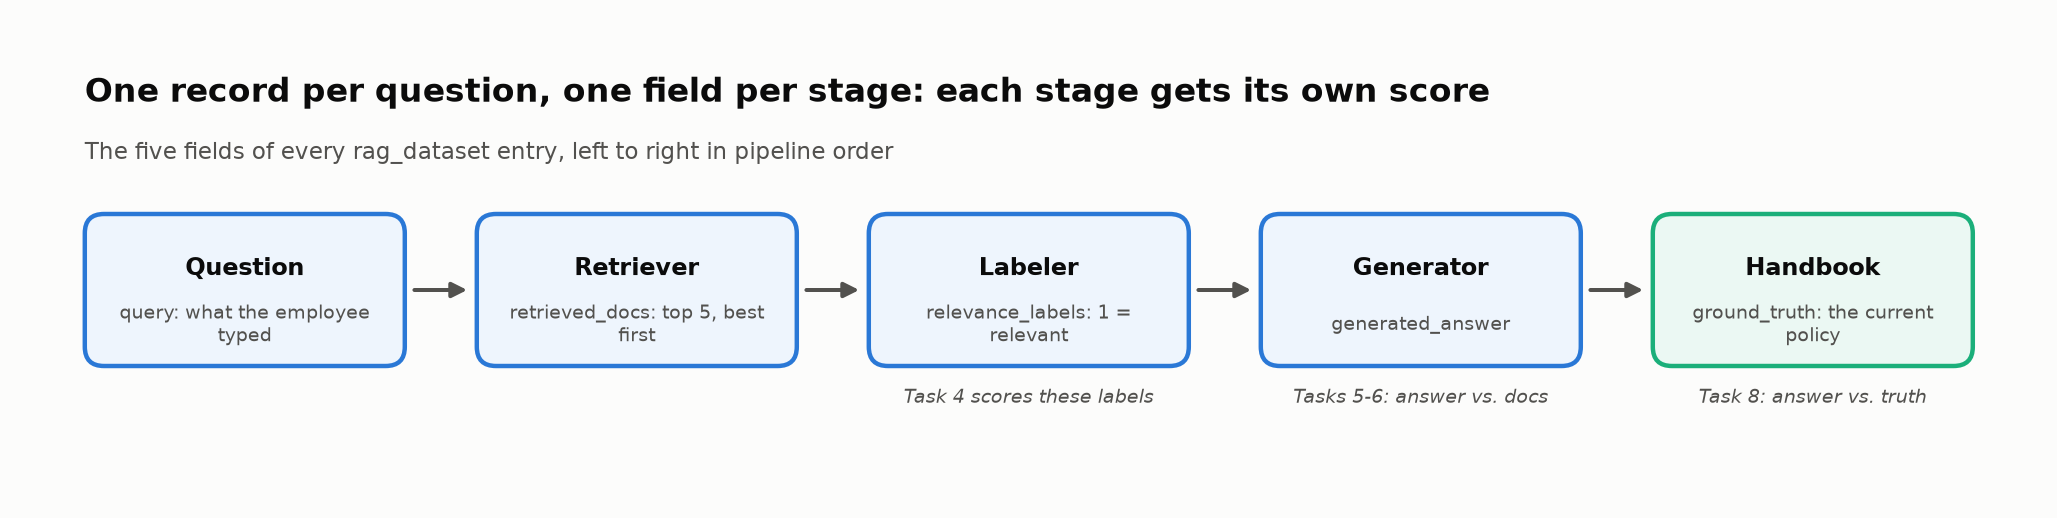
<sub>🖼️ *One field per stage, so each stage gets its own score.*</sub>

▶️ **Run** (code hidden, nothing to read): builds the 12 records.

In [ ]:
# @title 🧰 Fixtures: the 12 offline questions, each with 5 retrieved docs, a relevance label per doc, the system's answer and the handbook truth (hidden · 183 lines · expand to read any record)
# Synthetic RAG evaluation dataset — company policy Q&A system
# Each entry represents one COMPLETE query through the RAG pipeline:
#   query → retriever returns 5 docs → LLM generates answer
#
# Key fields to watch:
#   - relevance_labels: [1,0,0,0,0] means only the 1st doc is relevant
#   - Some queries have 0 relevant docs (retrieval failure!)
#   - Some generated answers contain fabricated information (generation failure!)

rag_dataset = [
    {
        "id": 1,
        "query": "How many PTO days do new employees get?",
        "retrieved_docs": [
            "New full-time employees receive 15 PTO days per year, accrued monthly starting from their hire date.",
            "PTO requests must be submitted at least 2 weeks in advance through the HR portal.",
            "After 5 years of service, employees receive an additional 5 PTO days per year.",
            "Company holidays include New Year's Day, Memorial Day, Independence Day, Labor Day, Thanksgiving, and Christmas.",
            "Part-time employees receive prorated PTO based on their scheduled hours."
        ],
        "relevance_labels": [1, 0, 0, 0, 0],  # Only doc 1 directly answers the question
        "generated_answer": "New full-time employees receive 15 PTO days per year, which accrue monthly starting from their hire date.",
        "ground_truth": "New full-time employees receive 15 PTO days per year, accrued monthly from hire date."
    },
    {
        "id": 2,
        "query": "What is the expense reimbursement limit for client dinners?",
        "retrieved_docs": [
            "Travel expenses must be submitted within 30 days of the trip using the expense management system.",
            "Office supply purchases under $50 do not require pre-approval.",
            "Client entertainment expenses are capped at $150 per person per meal and require a receipt and attendee list.",
            "Employees may expense co-working space fees up to $200/month when traveling.",
            "Annual team-building budgets are allocated at $500 per team member."
        ],
        "relevance_labels": [0, 0, 1, 0, 0],  # Relevant doc is at position 3 (not ideal ranking)
        "generated_answer": "Client dinner expenses are capped at $150 per person per meal. You'll need to submit a receipt and a list of attendees.",
        "ground_truth": "Client entertainment expenses are capped at $150 per person per meal, requiring a receipt and attendee list."
    },
    {
        "id": 3,
        "query": "Can I work remotely from another country?",
        "retrieved_docs": [
            "Remote work is available for all full-time employees with manager approval.",
            "Employees working remotely must maintain core hours of 10am-3pm in their local time zone.",
            "International remote work requires approval from both your manager and the Legal department due to tax and compliance implications. Requests must be submitted 30 days in advance.",
            "Home office equipment stipends of up to $1,000 are available for new remote workers.",
            "VPN access is required for all remote work to ensure secure connections to company systems."
        ],
        "relevance_labels": [0, 0, 1, 0, 0],  # Relevant doc buried at position 3
        "generated_answer": "Yes, you can work remotely from another country, but it requires approval from your manager and the Legal department. You need to submit the request 30 days in advance due to tax and compliance considerations.",
        "ground_truth": "International remote work requires manager and Legal approval, submitted 30 days in advance, due to tax and compliance implications."
    },
    {
        "id": 4,
        "query": "What happens if I exceed my PTO balance?",
        # ⚠️ RETRIEVAL FAILURE: None of these 5 docs are relevant to the question!
        "retrieved_docs": [
            "Company holidays include New Year's Day, Memorial Day, Independence Day, Labor Day, Thanksgiving, and Christmas.",
            "The employee assistance program provides free counseling sessions for stress management.",
            "Parking passes are available at a subsidized rate of $50/month in the company garage.",
            "The cafeteria offers a meal plan at $8/day for employees.",
            "Gym membership reimbursements are available up to $75/month."
        ],
        "relevance_labels": [0, 0, 0, 0, 0],  # ZERO relevant docs — complete retrieval failure
        "generated_answer": "If you exceed your PTO balance, additional days off will be unpaid. You should discuss extended leave options with HR, who can help you explore short-term disability or unpaid leave of absence.",
        "ground_truth": "Days taken beyond the PTO balance are unpaid. Employees must get manager approval for unpaid leave, and HR should be notified for payroll adjustment."
    },
    {
        "id": 5,
        "query": "How does the 401k match work?",
        "retrieved_docs": [
            "The company matches 401(k) contributions dollar-for-dollar up to 4% of base salary. Matching contributions vest over 3 years: 33% after year 1, 66% after year 2, 100% after year 3.",
            "Health insurance enrollment occurs during the annual open enrollment period in November.",
            "Employees can adjust their 401(k) contribution percentage at any time through the benefits portal.",
            "The company offers both traditional and Roth 401(k) options.",
            "Financial planning consultations are available quarterly at no cost to employees."
        ],
        "relevance_labels": [1, 0, 1, 1, 0],  # 3 relevant docs — strong retrieval
        "generated_answer": "The company provides a dollar-for-dollar 401(k) match up to 4% of your base salary. The match vests over 3 years at 33%, 66%, and 100%. You can choose between traditional and Roth 401(k) options and adjust contributions anytime via the benefits portal.",
        "ground_truth": "Dollar-for-dollar match up to 4% of base salary. 3-year vesting schedule (33/66/100%). Both traditional and Roth options available."
    },
    {
        "id": 6,
        "query": "What is the policy on bringing pets to the office?",
        # ⚠️ RETRIEVAL FAILURE + HALLUCINATION: No relevant docs, but the answer sounds confident!
        "retrieved_docs": [
            "The dress code is business casual Monday through Thursday and casual on Fridays.",
            "Visitors must sign in at the front desk and wear a visitor badge at all times.",
            "Food delivery orders should be picked up at the main lobby reception area.",
            "Conference rooms must be booked through the scheduling system at least 1 hour in advance.",
            "The building is non-smoking. Designated smoking areas are located in the parking structure."
        ],
        "relevance_labels": [0, 0, 0, 0, 0],  # ZERO relevant docs — another complete retrieval failure
        "generated_answer": "Pets are welcome in the office on designated Pet-Friendly Fridays. Dogs must be leashed in common areas and owners are responsible for cleanup. Please notify your floor manager in advance.",
        "ground_truth": "The company does not currently have a pet policy. Pets are not permitted in the office unless they are registered service animals."
    },
    {
        "id": 7,
        "query": "How do I report a workplace safety concern?",
        "retrieved_docs": [
            "Workplace safety concerns should be reported immediately to your manager or the Safety Committee via the anonymous reporting hotline at ext. 2222 or through the online safety portal.",
            "All employees must complete annual safety training by December 31st.",
            "Fire extinguishers are located at each stairwell entrance and in the kitchen areas.",
            "First aid kits are available in each break room and at the front desk.",
            "Emergency evacuation routes are posted by each elevator and stairwell."
        ],
        "relevance_labels": [1, 0, 0, 0, 0],  # Only doc 1 is relevant
        "generated_answer": "You can report safety concerns to your manager or use the anonymous Safety Committee hotline at extension 2222. There's also an online safety portal available for reporting.",
        "ground_truth": "Report to manager or Safety Committee via anonymous hotline (ext. 2222) or online safety portal."
    },
    {
        "id": 8,
        "query": "What are the rules for using company credit cards?",
        # ✅ PERFECT RETRIEVAL: All 5 docs are relevant!
        "retrieved_docs": [
            "Company credit cards are issued to employees at the director level and above. All charges must have a business justification and receipt.",
            "Personal charges on company credit cards are strictly prohibited and may result in disciplinary action.",
            "Monthly credit card statements must be reconciled and approved by the cardholder's manager within 15 business days.",
            "Lost or stolen company credit cards must be reported to Finance and the card issuer within 24 hours.",
            "Credit card limits are set based on role: Directors $5,000, VPs $10,000, C-suite $25,000."
        ],
        "relevance_labels": [1, 1, 1, 1, 1],  # ALL 5 docs relevant — best-case retrieval
        "generated_answer": "Company credit cards are available for directors and above. All charges need a business justification and receipt. Personal use is prohibited. Monthly statements must be reconciled within 15 business days with manager approval. Report lost cards to Finance within 24 hours.",
        "ground_truth": "Issued to directors+. Business justification and receipts required. No personal use. Monthly reconciliation within 15 business days. Report lost/stolen within 24 hours."
    },
    {
        "id": 9,
        "query": "Can I use my education stipend for an online bootcamp?",
        "retrieved_docs": [
            "The annual education stipend of $3,000 covers tuition, books, and course materials for job-related education. Eligible programs include accredited degrees, professional certifications, and approved online courses.",
            "Employees must receive manager approval before enrolling and submit receipts for reimbursement within 60 days of course completion.",
            "The mentorship program pairs junior employees with senior leaders for quarterly development conversations.",
            "Internal lunch-and-learn sessions are held every other Friday and count toward professional development hours.",
            "Conference attendance requires VP-level approval and is budgeted separately from the education stipend."
        ],
        "relevance_labels": [1, 1, 0, 0, 0],  # 2 relevant docs
        "generated_answer": "Yes, online bootcamps can be covered under the $3,000 annual education stipend as long as they are job-related. You'll need manager approval before enrolling. After completing the program, submit your receipts within 60 days for reimbursement.",
        "ground_truth": "The $3,000 education stipend covers job-related education including approved online courses. Manager approval required before enrollment, receipts due within 60 days."
    },
    {
        "id": 10,
        "query": "What is the parental leave policy?",
        # ⚠️ GENERATION FAILURE: Retrieval is great, but the answer changes "12 weeks" to "16 weeks"!
        "retrieved_docs": [
            "Full-time employees are eligible for 12 weeks of paid parental leave for the birth, adoption, or foster placement of a child. Leave must begin within 12 months of the qualifying event.",
            "Parental leave can be taken consecutively or split into two blocks with manager approval.",
            "During parental leave, all benefits including health insurance and 401(k) matching continue.",
            "Employees returning from parental leave are guaranteed the same or equivalent position.",
            "Short-term disability insurance covers 60% of salary for up to 26 weeks for medical conditions including pregnancy complications."
        ],
        "relevance_labels": [1, 1, 1, 1, 0],  # 4/5 relevant — very strong retrieval
        "generated_answer": "The company offers 16 weeks of fully paid parental leave for all new parents. You can take it all at once or split it into blocks. Your health insurance and retirement benefits continue during leave.",
        "ground_truth": "12 weeks paid parental leave for birth, adoption, or foster placement. Can be consecutive or split into two blocks. Benefits continue. Same/equivalent position guaranteed on return."
    },
    {
        "id": 11,
        "query": "How do I request a standing desk?",
        "retrieved_docs": [
            "Ergonomic equipment requests including standing desks, monitor arms, and keyboard trays can be submitted through the Facilities portal. Standard processing time is 5-7 business days.",
            "All new employees receive a standard desk setup including a monitor, keyboard, and mouse.",
            "The IT help desk handles requests for additional monitors, docking stations, and peripherals.",
            "Office furniture changes require approval from your floor coordinator to ensure space planning compliance.",
            "Height-adjustable desks are available in two models: manual crank ($400) and electric ($650). Both are covered by the company."
        ],
        "relevance_labels": [1, 0, 0, 1, 1],  # 3 relevant docs
        "generated_answer": "Submit a request through the Facilities portal for a standing desk. Processing takes 5-7 business days. You'll need your floor coordinator's approval. The company covers the cost — choose between a manual crank model or an electric one.",
        "ground_truth": "Request via Facilities portal (5-7 business days). Floor coordinator approval needed. Two models available: manual ($400) and electric ($650), both company-covered."
    },
    {
        "id": 12,
        "query": "What happens to my unvested stock options if I leave?",
        "retrieved_docs": [
            "Stock options vest over a 4-year schedule with a 1-year cliff. After the cliff, options vest monthly.",
            "Upon voluntary termination, employees have 90 days to exercise vested stock options. Unvested options are forfeited.",
            "In the event of involuntary termination without cause, the company may accelerate vesting at its discretion.",
            "Stock option grants are determined annually based on performance review and level.",
            "Tax implications of stock option exercise should be discussed with a personal financial advisor. The company provides access to a tax consultation service."
        ],
        "relevance_labels": [1, 1, 1, 0, 0],  # 3 relevant docs
        "generated_answer": "If you leave the company, your unvested stock options are forfeited. You have 90 days after departure to exercise any vested options. If you were terminated without cause, the company may choose to accelerate vesting, though this is discretionary.",
        "ground_truth": "Unvested options are forfeited on departure. 90 days to exercise vested options. Involuntary termination without cause may trigger discretionary accelerated vesting."
    },
]

▶️ **Run:** lists each query with its relevant-doc count → spot the ⚠️ rows.

In [ ]:
# 📂 The 12 records come from the 🧰 fixture cell above. Tag them, then list each query with its relevant-doc count.
for item in rag_dataset:
    item["source"] = "offline"   # written by the team from the docs (Task 8 adds a production sample)

# Display dataset summary — note how retrieval quality varies across queries
print(f"Loaded {len(rag_dataset)} RAG evaluation examples.\n")

for item in rag_dataset:
    n_relevant = sum(item["relevance_labels"])
    # Flag extreme cases to draw attention
    flag = "⚠️" if n_relevant == 0 else ("🟢" if n_relevant >= 3 else "  ")
    print(f"  {flag} Query {item['id']:2d}: \"{item['query'][:60]}...\"  "
          f"[{n_relevant}/5 relevant docs]")

In [ ]:
# @title 🔮 Predict: how many of the 12 answers abstain (decline to answer)?
pred_abstain = "— pick one —"  # @param ["— pick one —", "A) 0", "B) 2: the two with no relevant docs", "C) 4 or more"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** a refusal detector, run on all 12 answers. Note the 👀 line.

In [ ]:
# 🙊 Did the system ever decline? A refusal detector you'll reuse all lab long.
ABSTAIN_MARKERS = ("don't have enough information", "couldn't find", "could not find",
                   "not able to find", "i don't know", "no information")

def is_abstention(answer):
    """True if the answer declines to answer instead of making a claim."""
    a = answer.lower()
    # 👀 Look at: a phrase match, not a model; it only has to recognise "I don't know" in its usual wordings
    return any(marker in a for marker in ABSTAIN_MARKERS)

df = pd.DataFrame([{
    "id": item["id"],
    "query": item["query"],
    "n_relevant": sum(item["relevance_labels"]),          # how many of the 5 retrieved docs are relevant?
    "has_relevant": sum(item["relevance_labels"]) > 0,     # did retrieval find ANY relevant doc?
    "abstained": is_abstention(item["generated_answer"]),  # did the system decline to answer?
} for item in rag_dataset])

zero_ids = df.loc[~df["has_relevant"], "id"].tolist()
n_abstain = int(df["abstained"].sum())

▶️ **Run:** four tiles and the table → read the last tile.

In [ ]:
# 📊 The overview: how much evidence each query got, and how often the system declined
tiles([
    ("Queries", len(df), "offline test set", None),
    ("Relevant docs / query", f"{df['n_relevant'].mean():.1f}", "out of 5 retrieved", None),
    ("Zero relevant docs", len(zero_ids), f"queries {zero_ids}", "critical" if zero_ids else "good"),
    ("Answers that abstain", n_abstain, "said \"I don't know\"", "warning" if n_abstain == 0 else "good"),
])
insight(
    f"{len(df) - n_abstain} of {len(df)} answers are confident, including the {len(zero_ids)} with zero evidence",
    f"Queries {zero_ids} retrieved nothing relevant, yet the system still produced fluent, specific answers. "
    "A system that never says \"I don't know\" is telling you about its prompt, not its knowledge.\n"
    "**Rule of thumb:** count abstentions on day one. Zero abstentions on a test set that contains retrieval "
    "failures is a red flag, not a success.",
    kind="warning")
df

▶️ **Run:** grades your prediction.

In [ ]:
quiz("Your prediction: abstentions", pred_abstain, correct="A" if n_abstain == 0 else "B" if n_abstain == 2 else "C",
     why=f"{n_abstain} of {len(df)}. Queries {zero_ids} got five off-topic docs and answered as fluently as the rest.")

✋ **Your turn:** count the answers that should worry you most.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_blind = int((~df["has_relevant"] & ~df["abstained"]).sum())

In [ ]:
# ✋ Your turn: df has one row per query, with boolean columns has_relevant and abstained.
my_blind = ...   # ✏️ how many queries had NO relevant doc and answered anyway?

check("Confident answers with zero evidence", my_blind, _ref_blind,
      hint="Combine two conditions with & and ~ (not), then sum the True values.",
      success=f"{_ref_blind}: Queries {zero_ids} answered from five off-topic docs. The generator's tone doesn't depend on what it was given.")

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** Tiles: **12** queries · **2.0** relevant docs/query · **2** with zero ([4, 6]) · **0** abstain.
</details>

In [ ]:
# @title ❓ Quick check: zero of 12 answers abstain. What does that tell you?
answer = "— pick one —"  # @param ["— pick one —", "A) A red flag: Queries 4 and 6 had no evidence and should have declined", "B) The corpus covers every question", "C) The abstention detector is broken"]
quiz('Zero abstentions', answer, correct="A",
     why="A system that never says I don't know is telling you about its prompt, not its knowledge.",
     wrong={"B": 'Queries 4 and 6 retrieved zero relevant docs. The confidence came from the prompt.',
          "C": 'It catches real refusals: two production answers trip it in Part 2.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Count abstentions on day one: zero, on a set with retrieval failures, is a bug report.</b></font>

</td></tr></table>

---

## Task 3: 🔍 Think First — What Makes a RAG Response Trustworthy?

<big><b>Decide what “trustworthy” means before a metric decides for you.</b></big>

> 🎯 **Goal:** label three answers yourself: is each one **supported** by its retrieved docs?<br>
> ❓ **The question:** can an answer be right and still unsupported?<br>
> 👀 **Watch for:** Query 4.

▶️ **Run:** three answers next to the docs marked relevant.

In [ ]:
# Three answers next to the docs the retriever got right. Read them, then label them below.
for qid in (4, 7, 10):
    it = rag_dataset[qid - 1]
    relevant = [d for d, r in zip(it["retrieved_docs"], it["relevance_labels"]) if r]
    print(f"Query {qid}: {it['query']}")
    print("  Relevant docs:", relevant or "NONE (all 5 off-topic)")
    print("  Answer:       ", it["generated_answer"], "\n")

✋ **Your turn:** supported or not? (Not *true*: supported.)

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_supported = {4: False, 7: True, 10: False}

In [ ]:
# ✋ Your turn: True if every claim in the answer traces to a relevant doc above.
my_supported = ...   # ✏️ a dict like {4: True, 7: True, 10: True}, with your labels

check("Label it yourself: supported?", my_supported, _ref_supported,
      hint="Query 4 has no relevant doc at all. Compare Query 10's number with its first doc.",
      success="Only Query 7. Query 4's answer happens to match the handbook (extra days are unpaid), yet nothing retrieved supports it: right and supported are different questions.")

<!-- img: zero-evidence-twins.png -->
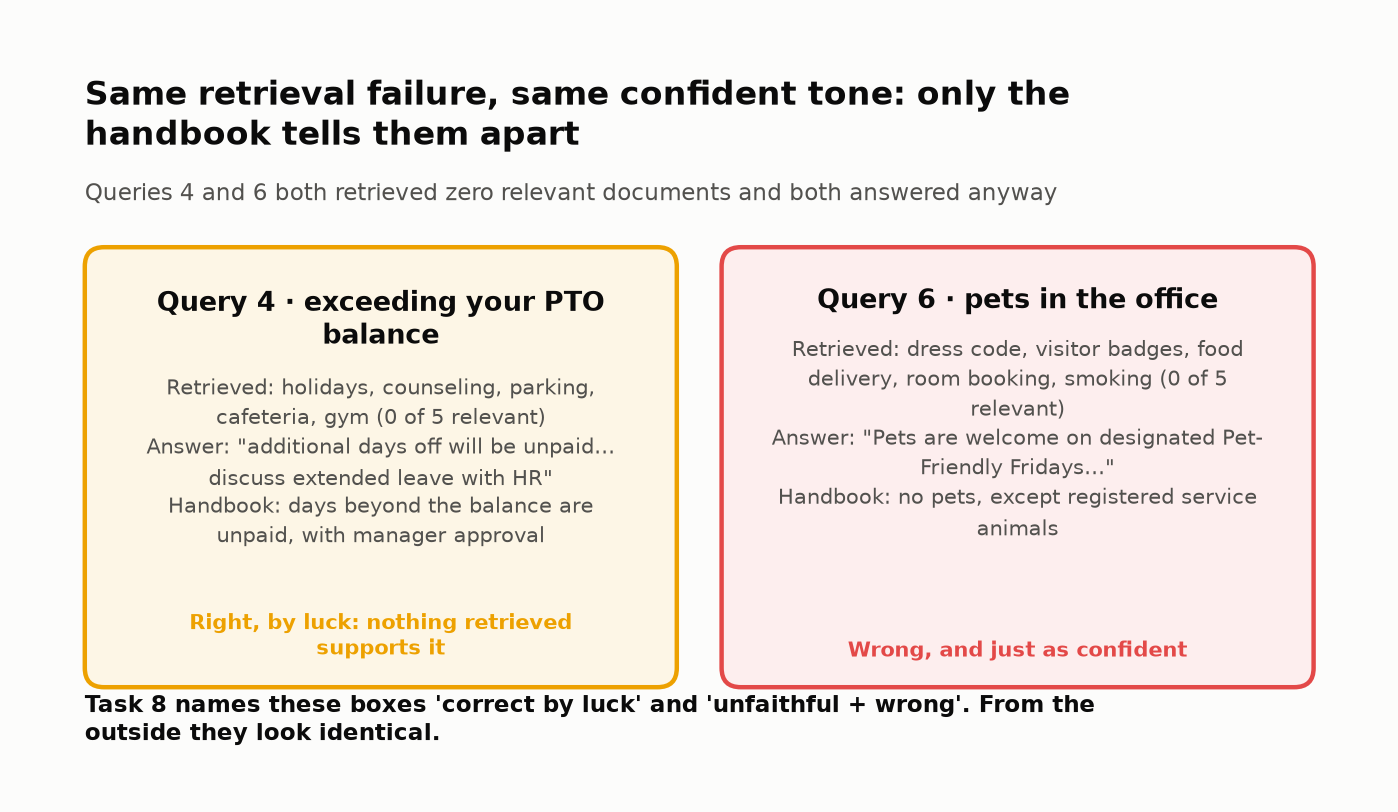
<sub>🖼️ *Same failure, same tone, opposite truth.*</sub>

🔍 **What just happened:** Query 4's rule was most likely absorbed in training; Query 6's "Pet-Friendly Fridays" is invented. The text can't tell them apart, so the lab <mark>measures the evidence, not the tone</mark>.

✍️ **Your call** (free text, double-click to edit): if you could measure only **one** thing about a RAG answer, what would it be? Should Query 4 have answered at all?

*Your answer…*

In [ ]:
# @title ❓ Quick check: Queries 4 and 6 both had zero relevant docs, and one answer matches the handbook. What in the text tells you which?
answer = "— pick one —"  # @param ["— pick one —", "A) Nothing: same tone, same fluency; only the evidence and the handbook differ", "B) The more specific answer is the invented one", "C) The answer that refers you to HR is the safe one"]
quiz('Spotting the lucky guess', answer, correct="A",
     why="An answer with no evidence behind it is a guess that sounds like policy, even on the days the guess is right.",
     wrong={"B": "Specificity is style, not truth: Query 8's very specific answer is correct.",
          "C": 'Hedging phrases come from training data, not from the docs.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Grade the evidence, not the tone: an unsupported answer is a guess, even when it's right.</b></font>

</td></tr></table>

---

🧭 **Where you are:** Act II of IV (Tasks 4–7): score each stage.

## Task 4: 📏 Compute Retrieval Metrics (Recall@K, Precision@K, nDCG, MRR)

<big><b>Headline the wrong metric and you tune rank order for a model that reads every chunk.</b></big>

> 🎯 **Goal:** four retrieval metrics per query, then pick the one to headline.<br>
> ❓ **The question:** which number belongs on the dashboard?<br>
> 👀 **Watch for:** Queries 2 and 3: the evidence sits at rank 3.

| Metric | Asks | Formula (K = 5) |
|---|---|---|
| **Recall@K** | did we **find** the relevant docs? | relevant in top K ÷ all relevant |
| **Precision@K** | how much **noise** came along? | relevant in top K ÷ K |
| **nDCG@K** | are relevant docs **ranked first**? | DCG ÷ ideal DCG; DCG = Σ rel ÷ log₂(rank + 1) |
| **MRR** | how deep is the **first** relevant doc? | mean of 1 ÷ its rank (0 if none) |

<!-- img: ranking-metrics.png -->
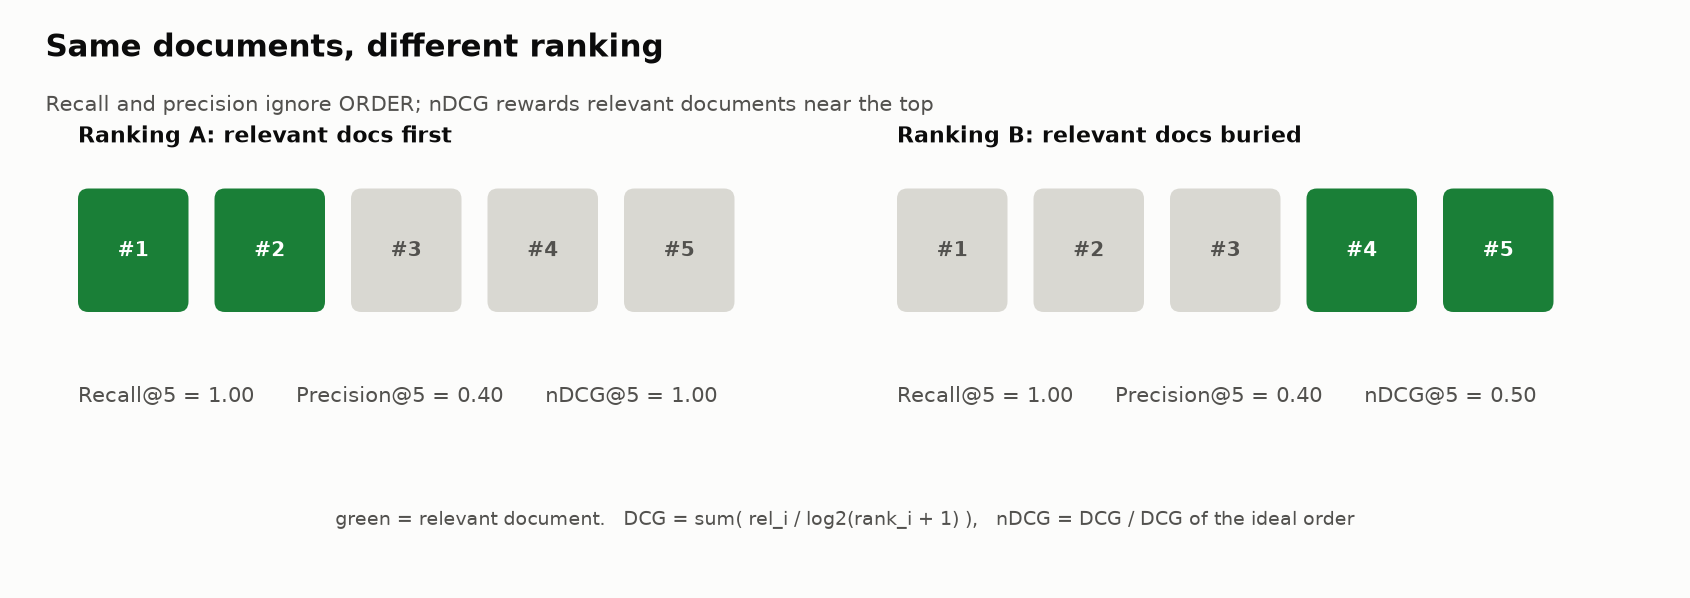

<sub>🖼️ *Same two relevant documents, different positions: only the rank-aware metrics (nDCG, MRR) notice*</sub>

> 📘 **Concept · Recall@K (here, a hit rate)**
>
> **What it is:** of the documents that *should* be retrieved, the fraction that appear in the top K. Only the 5 returned docs were labelled here, so "all relevant" means "relevant among those 5": Recall@5 is 1 if any came back and 0 if none did, and its mean over queries is the **hit rate**.
>
> **What it can't tell you:** whether the retrieved docs contain the answer (Task 9) or where they ranked. True recall needs labels across the whole **corpus** (every doc that could be retrieved), which Lab 04b has (`relevant_doc_ids`).
>
> **Anchor:** Query 4 retrieves holiday, counseling, parking, cafeteria and gym docs for a PTO question: Recall@5 = 0. Query 1 has one relevant doc in five and Query 8 has five in five; both score Recall@5 = 1.

In [ ]:
# @title 🔮 Predict: mean Precision@5 will be well below 0.5. Which single number belongs on the dashboard?
pred_headline = "— pick one —"  # @param ["— pick one —", "A) Precision@5", "B) nDCG@5", "C) MRR", "D) Recall@5, the hit rate"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** the four metrics → note the 👀 line in `ndcg_at_k`.

In [ ]:
# 📏 Four retrieval metrics. Each reads only the 0/1 relevance labels of the top K docs (K = 5 here).
def recall_at_k(relevance_labels, k=5):
    """Relevant docs in the top K ÷ all relevant docs (0 if there are none)."""
    total_relevant = sum(relevance_labels)
    return sum(relevance_labels[:k]) / total_relevant if total_relevant else 0.0

def precision_at_k(relevance_labels, k=5):
    """Relevant docs in the top K ÷ K."""
    return sum(relevance_labels[:k]) / k

def ndcg_at_k(relevance_labels, k=5):
    """DCG of this ranking ÷ DCG of the ideal ranking (all relevant docs first)."""
    # 👀 Look at: a relevant doc earns 1 / log2(rank + 1): full credit at rank 1, 0.63 at rank 2, 0.5 at rank 3
    dcg = sum(rel / np.log2(rank + 1) for rank, rel in enumerate(relevance_labels[:k], start=1))
    ideal = sorted(relevance_labels, reverse=True)[:k]
    idcg = sum(rel / np.log2(rank + 1) for rank, rel in enumerate(ideal, start=1))
    return dcg / idcg if idcg else 0.0

def mrr_at_k(relevance_labels, k=5):
    """1 ÷ rank of the first relevant doc in the top K (0 if none). Averaged over queries: MRR."""
    return next((1.0 / rank for rank, rel in enumerate(relevance_labels[:k], start=1) if rel), 0.0)

✋ **Your turn:** check `ndcg_at_k` by hand.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_ndcg = ndcg_at_k([0, 1, 0, 1, 0])

In [ ]:
# ✋ Your turn: relevant docs at ranks 2 and 4 → labels [0, 1, 0, 1, 0].
#    A relevant doc at rank r earns 1 / log2(r + 1). nDCG = this ranking's total ÷ the ideal ranking's total,
#    and the ideal ranking puts the same two docs at ranks 1 and 2.
my_ndcg = ...   # ✏️ one expression using np.log2

check("nDCG@5 by hand", my_ndcg, _ref_ndcg, tol=1e-3,
      hint="Add the credit for ranks 2 and 4; add the credit for ranks 1 and 2; divide the first sum by the second.",
      success=f"{_ref_ndcg:.2f}: the same two docs, ranked lower, lose a third of the credit. Recall@5 is still 1.0; only the rank metrics notice.")

▶️ **Run:** all 12 queries → compare the hit-rate and precision tiles.

In [ ]:
# ── Compute retrieval metrics for ALL 12 queries ──
results = []
for item in rag_dataset:
    labels = item["relevance_labels"]
    results.append({
        "id": item["id"],
        "query": item["query"][:50],
        "n_relevant": sum(labels),                 # how many relevant docs were in the results?
        "recall@5": recall_at_k(labels, 5),        # did we find the relevant ones? (a hit rate here)
        "precision@5": precision_at_k(labels, 5),  # how clean were the results?
        "ndcg@5": ndcg_at_k(labels, 5),            # were relevant docs ranked near the top?
        "mrr@5": mrr_at_k(labels, 5),              # how far down was the first relevant doc?
    })

metrics_df = pd.DataFrame(results)
print("📊 Retrieval Metrics per Query\n")
print(metrics_df.to_string(index=False, float_format="%.3f"))

means = metrics_df[["recall@5", "precision@5", "ndcg@5", "mrr@5"]].mean()
tiles([
    ("Mean Recall@5 (hit rate)", f"{means['recall@5']:.2f}", "evidence found at all", "warning"),
    ("Mean Precision@5", f"{means['precision@5']:.2f}", "share of the 5 docs that are relevant", None),
    ("Mean nDCG@5", f"{means['ndcg@5']:.2f}", "rank quality", None),
    ("MRR", f"{means['mrr@5']:.2f}", "1 / rank of first relevant doc", None),
])

▶️ **Run:** one chart and a card → which queries are doomed at retrieval?

In [ ]:
# ── 🎨 Visualize retrieval quality per query ──
ax = metrics_df.set_index("id")[["recall@5", "precision@5", "ndcg@5", "mrr@5"]].plot(
    kind="bar", figsize=(11, 4), width=0.8)
ax.set_xlabel("query id"); ax.set_ylabel("score"); ax.set_ylim(0, 1.32)
ax.set_title("Two queries retrieved nothing; the rest differ mostly in noise and rank")
ax.legend(ncol=4, loc="upper left")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

hit = metrics_df["recall@5"] > 0
buried = metrics_df.loc[(metrics_df["mrr@5"] > 0) & (metrics_df["mrr@5"] < 1), "id"].tolist()
n_noise = 5 * len(metrics_df) - int(metrics_df["n_relevant"].sum())
insight(
    f"Hit rate is {hit.mean():.0%} ({hit.sum()}/{len(hit)}), yet mean Precision@5 is only {means['precision@5']:.2f}. "
    "Which number matters?",
    f"Precision@5 is dragged down by the {n_noise} off-topic chunks that rode along, and MRR by queries {buried}, "
    "where the evidence sat below rank 1. But an LLM reads **all** K chunks; it doesn't stop at the first result "
    "like a person scanning search results. The queries that are doomed at the retrieval stage are the "
    f"{(~hit).sum()} with a hit rate of zero: {metrics_df.loc[~hit, 'id'].tolist()}.\n"
    "**Rule of thumb:** headline recall@K at the K you actually pass to the model (Anthropic's Contextual Retrieval "
    "study, 2024, used K = 20). Use precision, nDCG and MRR as tuning diagnostics, not as the quality score.")

▶️ **Run:** grades your prediction.

In [ ]:
quiz("Your prediction: the dashboard number", pred_headline, correct="D",
     why=f"Hit rate {hit.mean():.0%}. The LLM reads all K chunks, so only queries {metrics_df.loc[~hit, 'id'].tolist()} never had a chance; precision, nDCG and MRR are tuning diagnostics.")

🔍 **What just happened:** precision divides by K, so one relevant doc in five scores 0.20 even when it holds the whole answer. MRR and nDCG discount rank 3, which the LLM read anyway.

🎛️ **Experiment:** drag `K` to **2** and run. Which queries lose their evidence?

In [ ]:
# 🎛️ Send the model fewer chunks: which queries lose all their evidence? (5 = the lab's K)
K = 5  # @param {type:"slider", min:1, max:5, step:1}

lost = [it["id"] for it in rag_dataset if recall_at_k(it["relevance_labels"], k=K) == 0]
hit_k = 1 - len(lost) / len(rag_dataset)
print(f"K = {K}: hit rate {hit_k:.0%} · queries with no relevant doc in the top {K}: {lost}")

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** Tiles: hit rate **0.83** · Precision@5 **0.40** · nDCG@5 **0.73** · MRR **0.72**. At K = 2: `[2, 3, 4, 6]`.
</details>

In [ ]:
# @title ❓ Quick check: Queries 2 and 3 have MRR 0.33 and correct answers. When does that low MRR start to cost you?
answer = "— pick one —"  # @param ["— pick one —", "A) Now: MRR is the quality score", "B) Never: an LLM ignores rank", "C) When precision drops below 0.2", "D) When you send fewer than 3 chunks: their evidence falls out of the context"]
quiz('When rank starts to matter', answer, correct="D",
     why="Rank matters to an LLM only through K: evidence at rank 3 is read at K = 5 and lost at K = 2.",
     wrong={"A": 'The LLM read rank 3 and answered correctly.',
          "B": 'Rank stops mattering only while the evidence stays inside K. Try the slider at 2.',
          "C": 'Precision counts noise; it says nothing about where the evidence sits.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Headline recall at the K you send the model; rank metrics tune the retriever.</b></font>

</td></tr></table>

---

## Task 5: 🧠 Your Turn — Design Grounding Evaluation Criteria

<big><b>In a benefits answer, one changed number is the whole failure.</b></big>

> 🎯 **Goal:** decide what counts as **grounded**, then automate one criterion: the numbers.<br>
> ❓ **The question:** where is the line between paraphrase and fabrication?<br>
> 👀 **Watch for:** answers whose inventions contain no digits.

> 📘 **Concept · Faithfulness (also grounding, groundedness)**
>
> **What it is:** every claim in the answer is supported by the retrieved context. This task says "grounding"; from Task 6 on the lab says **faithfulness**; they mean the same thing.
>
> **What it can't tell you:** whether the answer is *true*. It checks the answer against the retrieved docs, not against reality: an answer copied faithfully from a stale doc is wrong, and a correct answer drawn from the model's training data is unfaithful.
>
> **Anchor:** Query 10's docs say 12 weeks and its answer says 16: unfaithful. Task 8 finds an answer that is perfectly faithful and still wrong.

✋ **Your turn:** four rewrites of Query 10's answer. Its doc says *"12 weeks of paid parental leave"*.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_grounded = {"A", "B"}

In [ ]:
# ✋ Your turn: which rewrites are GROUNDED (every claim traces to the doc)?
REWRITES = {"A": "Full-time employees get 12 weeks of paid parental leave.",
            "B": "You get about three months of paid leave when you have or adopt a child.",
            "C": "Full-time employees get 16 weeks of paid parental leave.",
            "D": "You get 12 weeks of paid parental leave, plus a $500 baby bonus."}

my_grounded = ...   # ✏️ a set of letters, e.g. {"A"}

check("Paraphrase vs fabrication", my_grounded, _ref_grounded,
      hint="Rewording a supported fact is fine. A changed fact is a distortion; an added fact no doc contains is a fabrication.",
      success="A and B. B rewords (paraphrase); C changes a fact (distortion); D adds one invented clause, and one is enough to make a partly grounded answer ungrounded.")

🧠 **Design (optional, 3 min, no grader):** your own 3–5 grounding criteria. ▶️ **Run:** prints them.

In [ ]:
# 🧠 Design: replace the "..." with your own criteria (3-5). Cover a changed fact, a partly grounded
# answer, helpful extras no doc supports, and the paraphrase/fabrication line.
my_grounding_criteria = [
    {"name": "...",              # e.g. "claim_attribution": does each claim trace to a doc?
     "description": "...", "scoring": "...", "failure_example": "..."},
    {"name": "...",              # e.g. "numerical_accuracy": do numbers match the source?
     "description": "...", "scoring": "...", "failure_example": "..."},
    {"name": "...",              # e.g. "no_unsupported_claims": nothing beyond the docs?
     "description": "...", "scoring": "...", "failure_example": "..."},
]

print("📋 My Grounding Evaluation Criteria:\n")
for i, criterion in enumerate(my_grounding_criteria, 1):
    print(f"  {i}. {criterion['name']}")
    print(f"     Description:    {criterion['description']}")
    print(f"     Scoring:        {criterion['scoring']}")
    print(f"     Failure looks like: {criterion['failure_example']}")
    print()

In [ ]:
# @title 🔮 Predict: one criterion as code: every number in the answer must appear in the retrieved docs. How many of the 12 answers will it flag?
pred_number_flags = "— pick one —"  # @param ["— pick one —", "A) 0", "B) 1", "C) 3: every answer with a problem"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** the 10-line number check → note the 👀 set difference.

In [ ]:
# 🔢 One grounding criterion you can automate in 10 lines:
# every NUMBER in the answer (amounts, days, percentages) must appear somewhere in the retrieved docs.
NUM_RE = re.compile(r"\d[\d,]*(?:\.\d+)?")

def numbers_in(text):
    """All numbers in a string, normalized ("$3,000" → "3000")."""
    return {n.replace(",", "") for n in NUM_RE.findall(text)}

def unsupported_numbers(item):
    context = " ".join(item["retrieved_docs"])
    # 👀 Look at: a set difference; any number in the answer that no retrieved doc contains is a claim with no source
    return sorted(numbers_in(item["generated_answer"]) - numbers_in(context))

number_flags = {it["id"]: unsupported_numbers(it) for it in rag_dataset}
flagged = {qid: nums for qid, nums in number_flags.items() if nums}
with_numbers = [it["id"] for it in rag_dataset if numbers_in(it["generated_answer"])]
no_number_fabrications = [it["id"] for it in rag_dataset
                          if sum(it["relevance_labels"]) == 0 and not numbers_in(it["generated_answer"])]

print(f"Answers containing numbers: {len(with_numbers)}/{len(rag_dataset)}")
for qid, nums in flagged.items():
    print(f"  🚩 Query {qid}: {nums} appear in the answer but nowhere in the retrieved docs")

insight(
    f"A 10-line number check flags {len(flagged)} of {len(rag_dataset)} answers: "
    + ", ".join(f"Query {q} ({', '.join(n)})" for q, n in flagged.items()),
    f"That's the 12 → 16 weeks distortion, caught deterministically, with no model. It checked {len(with_numbers)} "
    f"answers that contain numbers and raised no false alarms. It says nothing about queries {no_number_fabrications}, "
    "whose fabrications contain no numbers: a deterministic check is precise, not complete.\n"
    "**Rule of thumb:** in benefits, payroll and tax answers the numbers are the claims that hurt. Verify numbers, "
    "dates and amounts with exact checks first, then spend model-based checks on what's left.")

▶️ **Run:** grades your prediction.

In [ ]:
quiz("Your prediction: number-check flags", pred_number_flags, correct={0: "A", 1: "B"}.get(len(flagged), "C"),
     why=f"{len(flagged)}: only Query 10's '16'. Queries {no_number_fabrications} invent policy with no digits, so there's nothing to subtract.")

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** `Answers containing numbers: 10/12` · `🚩 Query 10: ['16'] …`
</details>

In [ ]:
# @title ❓ Quick check: the number check flagged only Query 10. Queries 4 and 6 are invented too. Why did it miss them?
answer = "— pick one —"  # @param ["— pick one —", "A) The regex is buggy", "B) Their inventions contain no digits: an exact check is precise, not complete", "C) Queries with no relevant docs are skipped"]
quiz("What the number check can't see", answer, correct="B",
     why="Deterministic checks catch exactly what they look for. Spend model-based checks on what is left.",
     wrong={"A": 'It found every number in the 10 answers that contain one.',
          "C": 'It compares against all 5 retrieved docs; those answers just had no numbers to subtract.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Verify numbers with code first: in a benefits answer, the number is the claim.</b></font>

</td></tr></table>

---

## Task 6: 🧪 Implement Faithfulness Scoring

<big><b>A scorer wired to an alert is only as good as its miss and false-alarm rates.</b></big>

> 🎯 **Goal:** two faithfulness scorers, then where each is wrong.<br>
> ❓ **The question:** what does each scorer miss, and what does it flag that's fine?<br>
> 👀 **Watch for:** Query 10's word-overlap score.

**Word overlap:** share of the answer's words, minus **stop words** (*the, of, not…*), found in the relevant docs. **Miss** = bad answer passed; **false alarm** = good answer flagged.

> 📘 **Concept · NLI entailment**
>
> **What it is:** a natural language inference (NLI) model reads a **premise** (here, the relevant docs) and a **hypothesis** (the answer) and returns three probabilities: **entailment** (the premise supports it), **contradiction**, and **neutral** (neither). Faithfulness = P(entailment). This lab's model is a **cross-encoder**: it reads both texts in one pass, which is more accurate than comparing two separate **embeddings** (one vector per text).
>
> **What it can't tell you:** which claim failed, or whether the premise is current. Asked about a long, multi-claim answer in one pass, a small model often says "neutral" even when every claim is supported.
>
> **Anchor:** with Query 8's doc "Personal charges on company credit cards are strictly prohibited" as the premise, "Personal use is prohibited" is entailment, "You may put personal charges on the card" is contradiction, and "Cards have a $5,000 limit" is neutral.

<!-- img: nli.png -->
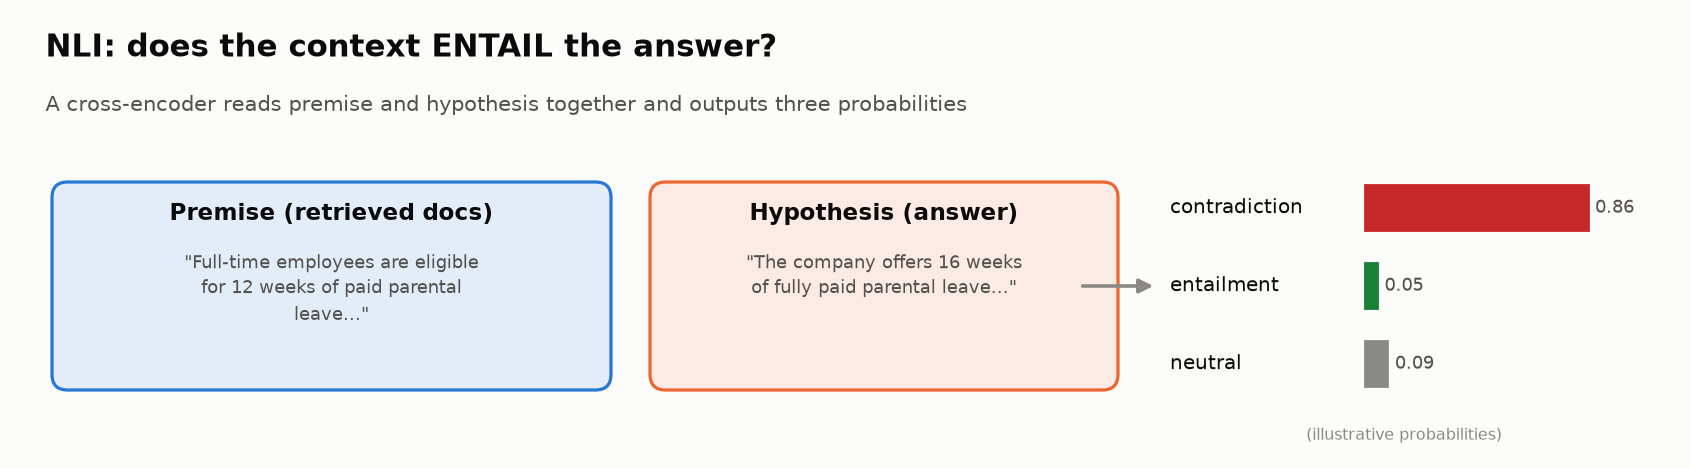

<sub>🖼️ *How an NLI cross-encoder scores one (premise, hypothesis) pair*</sub>

▶️ **Run** (code hidden): `tokenize()` and the stop-word list.

In [ ]:
# @title 🧰 tokenize() and STOP_WORDS, the stop-word list the word-overlap scorer uses (hidden · 16 lines · expand if curious)
def tokenize(text):
    """Lowercased set of words (letters, digits and underscores)."""
    return set(re.findall(r'\b\w+\b', text.lower()))

# Very common words that say little about a text's topic. Search engines drop them; so does this scorer.
STOP_WORDS = {'the', 'a', 'an', 'is', 'are', 'was', 'were', 'be', 'been', 'being',
              'have', 'has', 'had', 'do', 'does', 'did', 'will', 'would', 'could',
              'should', 'may', 'might', 'shall', 'can', 'to', 'of', 'in', 'for',
              'on', 'with', 'at', 'by', 'from', 'as', 'into', 'through', 'during',
              'and', 'but', 'or', 'nor', 'not', 'so', 'yet', 'both', 'either',
              'neither', 'each', 'every', 'all', 'any', 'few', 'more', 'most',
              'other', 'some', 'such', 'no', 'only', 'own', 'same', 'than',
              'too', 'very', 'just', 'because', 'if', 'when', 'where', 'how',
              'what', 'which', 'who', 'whom', 'this', 'that', 'these', 'those',
              'i', 'me', 'my', 'we', 'our', 'you', 'your', 'he', 'him', 'his',
              'she', 'her', 'it', 'its', 'they', 'them', 'their'}

▶️ **Run:** Method 1, word overlap → Query 1 high, Query 6 zero.

In [ ]:
# Method 1: word overlap. What share of the answer's content words also appear in the RELEVANT docs?
def rule_based_faithfulness(answer, retrieved_docs, relevance_labels):
    """0-1: share of the answer's content words (stop words removed) found in the relevant docs."""
    relevant_docs = [doc for doc, rel in zip(retrieved_docs, relevance_labels) if rel == 1]
    answer_words = tokenize(answer) - STOP_WORDS
    if not relevant_docs:                       # no evidence: a substantive answer must be invented
        return 0.0 if len(answer_words) > 3 else 0.5
    if not answer_words:
        return 1.0
    context_words = set().union(*(tokenize(doc) - STOP_WORDS for doc in relevant_docs))
    # 👀 Look at: a word counts as supported if it appears ANYWHERE in the docs, whatever the doc says around it
    return len(answer_words & context_words) / len(answer_words)

for idx, name, expect in [(0, "Query 1 (PTO days)", "high: the answer mirrors the doc"),
                          (5, "Query 6 (pet policy)", "low: no relevant docs, so nothing supports it")]:
    it = rag_dataset[idx]
    score = rule_based_faithfulness(it["generated_answer"], it["retrieved_docs"], it["relevance_labels"])
    print(f"Rule-based faithfulness for {name}: {score:.3f}  (expected {expect})")
print("\n✅ Rule-based faithfulness scorer ready.")

▶️ **Run:** Method 2, NLI (downloads ~90 MB once) → the same two queries.

In [ ]:
# Method 2: NLI. Do the relevant docs ENTAIL the answer? (premise = relevant docs, hypothesis = answer)
from sentence_transformers import CrossEncoder
nli_model = CrossEncoder("cross-encoder/nli-MiniLM2-L6-H768", max_length=512)   # ~90 MB, downloaded once
NLI_LABELS = ["contradiction", "entailment", "neutral"]                          # the model's output order
print("✅ NLI cross-encoder loaded: nli-MiniLM2-L6-H768")

def nli_faithfulness(answer, retrieved_docs, relevance_labels):
    """P(the relevant docs entail the answer), plus P(contradiction) and the winning label."""
    relevant_docs = [doc for doc, rel in zip(retrieved_docs, relevance_labels) if rel == 1]
    if not relevant_docs:                                  # nothing to check against
        return {"entailment_score": 0.0, "label": "no_context", "scores": [0, 0, 0]}
    # 👀 Look at: ONE pair, all relevant docs vs. the whole answer; softmax turns 3 logits into probabilities
    scores = nli_model.predict([(" ".join(relevant_docs), answer)], apply_softmax=True)[0]
    return {"entailment_score": float(scores[1]), "contradiction_score": float(scores[0]),
            "label": NLI_LABELS[int(np.argmax(scores))], "scores": [float(s) for s in scores]}

for idx, name in [(0, "Query 1 (PTO days)"), (5, "Query 6 (pet policy)")]:
    it = rag_dataset[idx]
    r = nli_faithfulness(it["generated_answer"], it["retrieved_docs"], it["relevance_labels"])
    print(f"\nNLI faithfulness for {name}:\n  Entailment score: {r['entailment_score']:.3f}\n  Predicted label:  {r['label']}")

In [ ]:
# @title 🔮 Predict: Query 10 swaps 12 weeks for 16 and keeps the doc's other words. Its word-overlap score will be…
pred_q10_overlap = "— pick one —"  # @param ["— pick one —", "A) below 0.3", "B) 0.3 to 0.6", "C) above 0.6"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** both scorers on all 12 → find Query 10's row.

In [ ]:
# Head-to-head: both scorers on all 12 answers. Where they disagree, at least one of them is wrong.
comparison = []
for item in rag_dataset:
    args = (item["generated_answer"], item["retrieved_docs"], item["relevance_labels"])
    nli_result = nli_faithfulness(*args)
    comparison.append({
        "id": item["id"], "query": item["query"][:45] + "...", "n_relevant": sum(item["relevance_labels"]),
        "rule_based": rule_based_faithfulness(*args),                       # word overlap (0-1)
        "nli_entailment": nli_result["entailment_score"],                   # P(entailment) (0-1)
        "nli_contradiction": nli_result.get("contradiction_score", 0.0),    # P(contradiction)
        "nli_label": nli_result["label"],
    })
comp_df = pd.DataFrame(comparison)
print("📊 Faithfulness Comparison: Rule-Based vs NLI\n")
print(comp_df.to_string(index=False, float_format="%.3f"))

has_context = comp_df[comp_df["n_relevant"] > 0]   # no-context queries would drag both means toward 0
print(f"\n--- Method Averages (excluding no-context queries) ---")
print(f"  Rule-based mean:     {has_context['rule_based'].mean():.3f}")
print(f"  NLI entailment mean: {has_context['nli_entailment'].mean():.3f}")

▶️ **Run:** grades your prediction.

In [ ]:
_q10 = comp_df.set_index("id").loc[10, "rule_based"]
quiz("Your prediction: Query 10's word overlap", pred_q10_overlap, correct="A" if _q10 < 0.3 else "B" if _q10 <= 0.6 else "C",
     why=f"{_q10:.2f}, above a 0.5 pass line: '16' is one changed word among many shared ones. NLI gave it {comp_df.set_index('id').loc[10, 'nli_entailment']:.2f}.")

✋ **Your turn:** evaluate the evaluator.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_c = comp_df.set_index("id")
_ref_false_alarms = {i for i in _c.index if i not in {4, 6, 10} and _c.loc[i, "nli_entailment"] < 0.5}

In [ ]:
# ✋ Your turn: we read the docs by hand. Answers 4, 6 and 10 are unfaithful; the other 9 are faithful.
# 👀 Look at: without this hand-labelled set there is nothing to measure a scorer against
KNOWN_UNFAITHFUL = {4, 6, 10}
c = comp_df.set_index("id")
faithful_ids = [i for i in c.index if i not in KNOWN_UNFAITHFUL]

my_false_alarms = ...   # ✏️ the faithful ids that NLI flags (c.loc[i, "nli_entailment"] below 0.5)

check("NLI's false alarms", my_false_alarms, _ref_false_alarms,
      hint="Loop over faithful_ids and keep the ones whose entailment is under 0.5.",
      success=f"Queries {sorted(_ref_false_alarms)}: {len(_ref_false_alarms)} of 9 good answers flagged. NLI catches Query 10, then cries wolf a third of the time.")

▶️ **Run:** both scorers' errors as tiles.

In [ ]:
# 🧪 Misses and false alarms, using KNOWN_UNFAITHFUL, c and faithful_ids from the exercise cell above
nli_false_alarms = [i for i in faithful_ids if c.loc[i, "nli_entailment"] < 0.5]
rb_misses = [i for i in KNOWN_UNFAITHFUL if c.loc[i, "rule_based"] >= 0.5]
tiles([
    ("Query 10, word overlap", f"{c.loc[10, 'rule_based']:.2f}", "looks faithful", "critical"),
    ("Query 10, NLI entailment", f"{c.loc[10, 'nli_entailment']:.2f}", "caught the distortion", "good"),
    ("NLI false alarms", f"{len(nli_false_alarms)}/{len(faithful_ids)}", f"good answers scored < 0.5: {nli_false_alarms}", "warning"),
    ("Word-overlap misses", f"{len(rb_misses)}/{len(KNOWN_UNFAITHFUL)}", f"bad answers scored ≥ 0.5: {sorted(rb_misses)}", "warning"),
])
insight(
    f"NLI caught Query 10 (entailment {c.loc[10, 'nli_entailment']:.2f}) that word overlap waved through at "
    f"{c.loc[10, 'rule_based']:.2f}, and then flagged {len(nli_false_alarms)} of {len(faithful_ids)} good answers",
    f"Queries {nli_false_alarms} are faithful, but a small NLI model reading a long, multi-claim answer in one pass "
    "can't confirm them. Each scorer has a measurable **miss rate** and **false-alarm rate**, and you only learn "
    "them by running the scorer on answers you've already judged.\n"
    "**Rule of thumb:** before wiring a faithfulness scorer to an alert, run it on 20–50 hand-labelled answers and "
    "report misses *and* false alarms (TPR/TNR), not its average score.")

🔍 **What just happened:** the scorers fail in opposite directions: word overlap hides a changed number among shared words; NLI gets one big question per answer, and for Query 8 (five claims, four docs) says "neutral".

<!-- img: q8-one-verdict.png -->
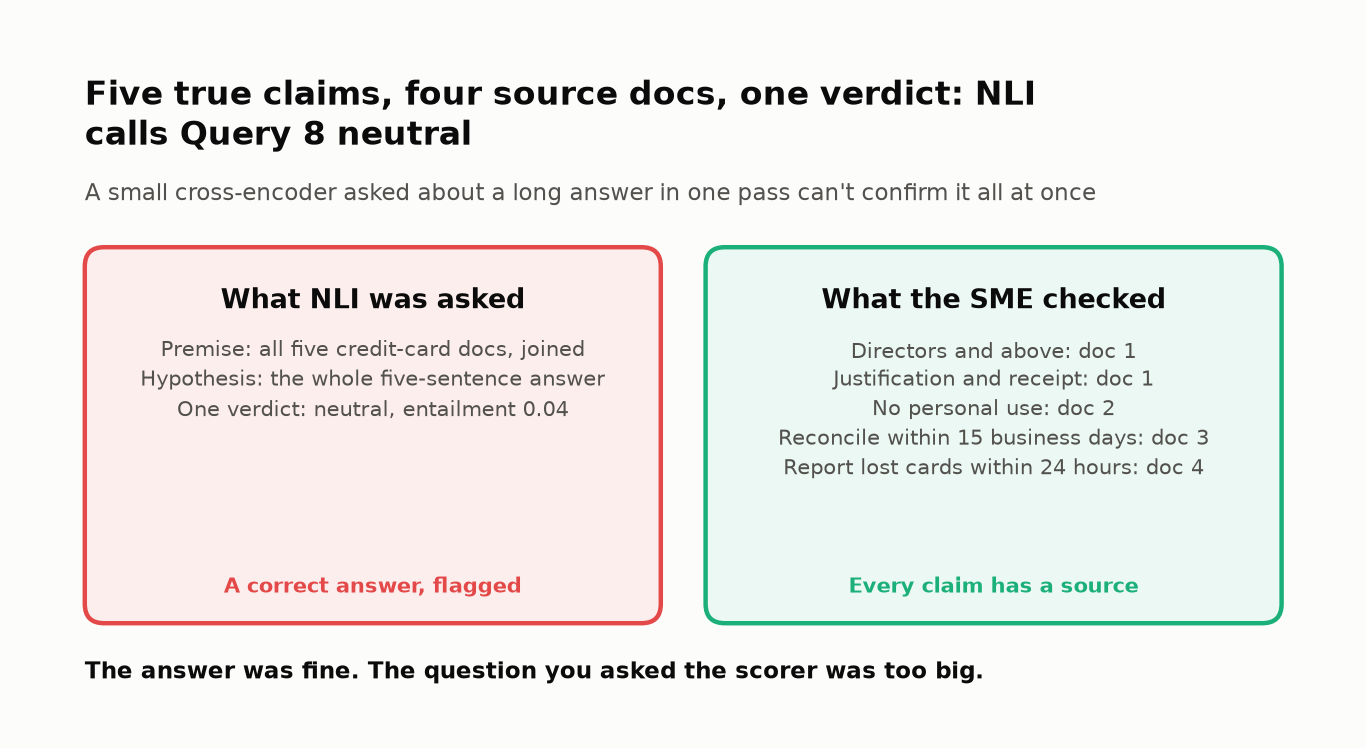
<sub>🖼️ *The false alarm comes from the size of the question. Challenge 5 asks claim by claim.*</sub>

**🧨 One more answer: a flat denial.** Built only from Query 10's own doc words: *"Employees are not eligible for 12 weeks of paid parental leave."*

In [ ]:
# @title 🔮 Predict: the denial's word-overlap score will be…
pred_denial = "— pick one —"  # @param ["— pick one —", "A) below 0.3", "B) 0.3 to 0.7", "C) above 0.9"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** word overlap, the number check and NLI on the denial.

In [ ]:
# 🧨 A flat denial of the parental-leave policy, built only from the doc's own words
denial = "Employees are not eligible for 12 weeks of paid parental leave."
q10 = rag_dataset[9]
den_overlap = rule_based_faithfulness(denial, q10["retrieved_docs"], q10["relevance_labels"])
den_nli = nli_faithfulness(denial, q10["retrieved_docs"], q10["relevance_labels"])
den_numbers = unsupported_numbers({**q10, "generated_answer": denial})
print(f"Words the overlap scorer threw away: {sorted(tokenize(denial) & STOP_WORDS)}")

tiles([
    ("Word overlap", f"{den_overlap:.2f}", "a perfect score", "critical"),
    ("Number check", "pass" if not den_numbers else "flag", "12 is in the docs", "critical" if not den_numbers else "good"),
    ("NLI label", den_nli["label"], f"P(contradiction) = {den_nli['contradiction_score']:.2f}", "good"),
])
insight(
    f"A sentence that denies the policy scores {den_overlap:.2f} on word overlap",
    "`not` is on the stop-word list, so the scorer deletes the one word that reverses the meaning, and every word "
    f"left is in the doc. NLI reads the sentence whole and calls it a **contradiction** ({den_nli['contradiction_score']:.2f}). "
    "Stop-word lists were built for search, where *not* says little about the topic; in an evaluator it *is* the claim.\n"
    "**Rule of thumb:** never gate on a bag-of-words score (one that only counts words). If you keep one as a cheap "
    "pre-filter, take negations (not, no, nor, neither) off its stop list.",
    kind="surprise")

▶️ **Run:** grades your prediction.

In [ ]:
quiz("Your prediction: the denial's overlap", pred_denial, correct="A" if den_overlap < 0.3 else "B" if den_overlap <= 0.7 else "C",
     why=f"{den_overlap:.2f}: `not` is a stop word, so the scorer deletes the one word that reverses the meaning. NLI: {den_nli['label']}.")

<!-- img: overlap-blind-spot.png -->
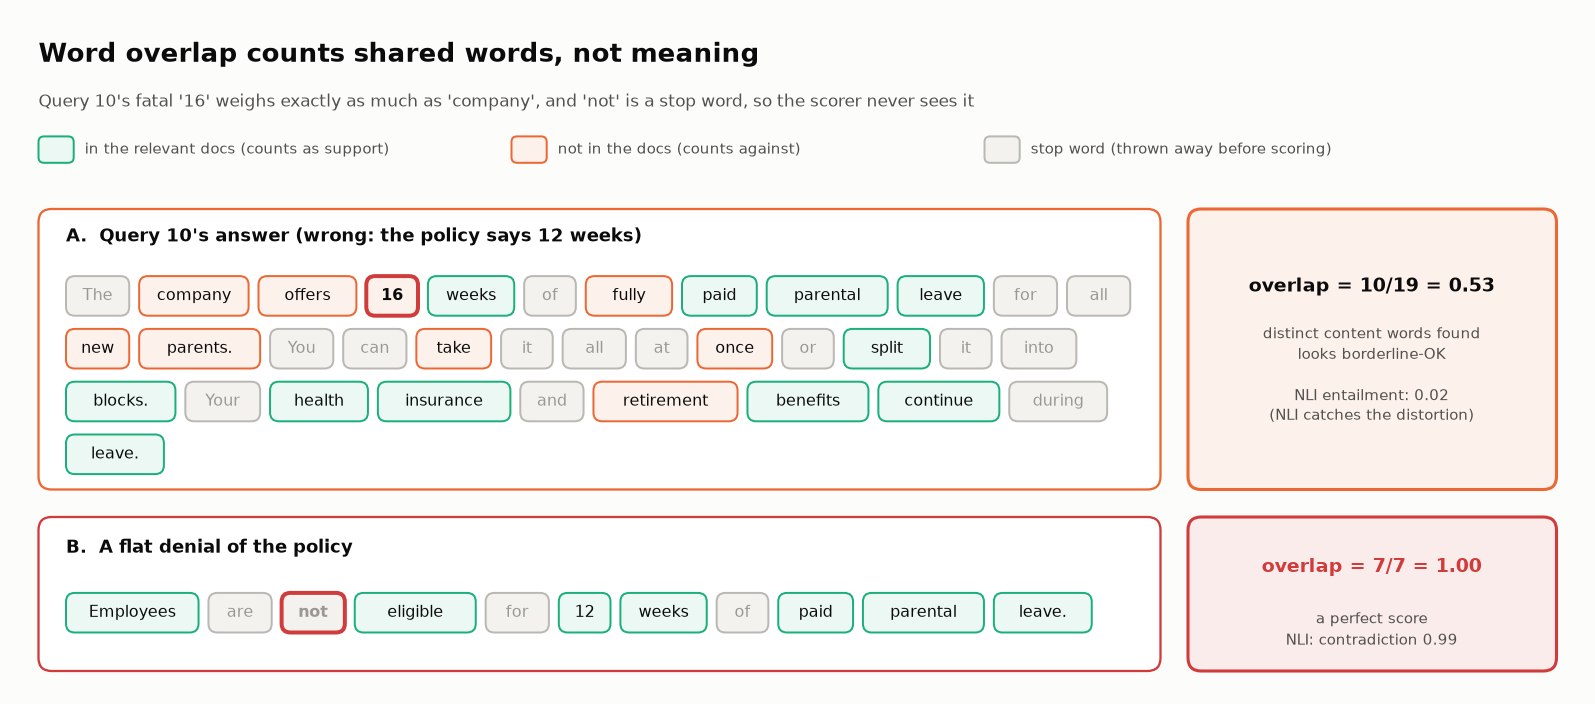
<sub>🖼️ *Every word counts the same, and "not" is never counted.*</sub>

<font color="#d03b3b"><b>⚠️ Never gate on a score that only counts words.</b></font>

🎛️ **Experiment:** tick `KEEP_NEGATIONS` and run. Does keeping `not` fix the scorer?

In [ ]:
# 🎛️ Keep negation words when scoring the denial (unticked = the lab's stop list)
KEEP_NEGATIONS = False  # @param {type:"boolean"}

stops = STOP_WORDS - {"not", "no", "nor", "neither"} if KEEP_NEGATIONS else STOP_WORDS
words = tokenize(denial) - stops
docs = [d for d, r in zip(q10["retrieved_docs"], q10["relevance_labels"]) if r]
context = set().union(*(tokenize(d) - stops for d in docs))
print(f"KEEP_NEGATIONS = {KEEP_NEGATIONS}: overlap {len(words & context) / len(words):.2f} · unmatched: {sorted(words - context)}")

🔍 **What just happened:** with `not` kept, the denial still scores 0.88: seven of eight words match. Fixing the stop list doesn't fix a bag of words.

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** Query 10: overlap **0.53**, NLI **0.02**. NLI false alarms **3/9** ([2, 8, 12]); overlap misses **1/3** ([10]). Denial: overlap **1.00**, number check pass, NLI **contradiction** (0.99).
</details>

🗣️ **Say it to a colleague:** "Until you've measured its misses and false alarms on labelled answers, you have a number, not a scorer."

In [ ]:
# @title ❓ Quick check: NLI called Query 8's faithful, five-claim answer neutral (0.04). Why?
answer = "— pick one —"  # @param ["— pick one —", "A) The answer is unfaithful", "B) NLI can't read numbers", "C) The credit-card docs contradict each other", "D) One verdict for five claims from four docs: the question was too big for a small model"]
quiz("Query 8's false alarm", answer, correct="D",
     why="Ask a small NLI model one question per claim, not one per answer (Challenge 5).",
     wrong={"A": 'The SME confirms every claim; each traces to one of the four docs.',
          "B": 'It caught 12 → 16 in Query 10.',
          "C": 'The five credit-card docs agree; they cover different rules.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Never gate on a scorer whose miss and false-alarm rates you haven't measured.</b></font>

</td></tr></table>

---

## Task 7: 🔬 Analyze Traced RAG Examples

<big><b>A wrong root cause sends an engineer to the wrong file.</b></big>

> 🎯 **Goal:** one **trace** per query, then a root cause: retrieval or generation?<br>
> ❓ **The question:** 10 of 12 answers are correct. How many will the classifier call NO FAILURE?<br>
> 👀 **Watch for:** the MIXED bucket.

In [ ]:
# @title 🔮 Predict: 10 of the 12 offline answers are correct. How many will the classifier mark NO FAILURE?
pred_no_failure = "— pick one —"  # @param ["— pick one —", "A) 9 to 10", "B) 6 to 8", "C) 5 or fewer"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run** (code hidden): `analyze_trace()` averages the two faithfulness scores and packs one trace per query.

In [ ]:
# @title 🧰 analyze_trace(): averages the two faithfulness scores, measures overlap with the ground truth, packs one trace dict (hidden · 27 lines · expand if curious)
def analyze_trace(item, rb_score, nli_score):
    """One trace per query: retrieval status, generation status, root cause, and the scores behind them."""
    n_relevant = sum(item["relevance_labels"])
    avg_faithfulness = (rb_score + nli_score) / 2             # both faithfulness signals, equally weighted
    gt_words = tokenize(item["ground_truth"]) - STOP_WORDS     # word-overlap proxy for correctness
    ans_words = tokenize(item["generated_answer"]) - STOP_WORDS
    gt_overlap = len(gt_words & ans_words) / len(gt_words) if gt_words else 1.0

    retrieval_status = classify_retrieval(n_relevant)
    generation_status = classify_generation(n_relevant, avg_faithfulness, gt_overlap, len(ans_words))
    return {
        "id": item["id"],
        "query": item["query"],
        "retrieval_status": retrieval_status,
        "retrieval_diagnosis": {"❌ FAILURE": "No relevant documents retrieved",
                                "⚠️ WEAK": f"Only {n_relevant}/5 relevant doc(s) — limited context",
                                "✅ GOOD": f"{n_relevant}/5 relevant docs retrieved"}[retrieval_status],
        "generation_status": generation_status,
        "generation_diagnosis": {"✅ GOOD": "Answer is faithful to context and matches ground truth",
                                 "❌ HALLUCINATION": "Generated substantive answer without relevant context",
                                 "❌ UNFAITHFUL": "Answer contains claims not supported by retrieved docs",
                                 "⚠️ PARTIAL": "Answer partially supported — some claims may be unsupported"}[generation_status],
        "root_cause": root_cause(retrieval_status, generation_status),
        "faithfulness_rb": rb_score,
        "faithfulness_nli": nli_score,
        "gt_overlap": gt_overlap,
    }

▶️ **Run:** the classifier: three small rules → note the 👀 line.

In [ ]:
# 🔬 The root-cause classifier is three small rules. Each threshold is an assumption about what "failure" means.
def classify_retrieval(n_relevant):
    if n_relevant == 0:
        return "❌ FAILURE"
    # 👀 Look at: one relevant doc out of five is filed as WEAK, even when that one doc holds the whole answer
    return "⚠️ WEAK" if n_relevant <= 1 else "✅ GOOD"

def classify_generation(n_relevant, avg_faithfulness, gt_overlap, n_answer_words):
    if avg_faithfulness >= 0.6 and gt_overlap >= 0.4:      # faithful AND close to the ground truth
        return "✅ GOOD"
    if n_relevant == 0 and n_answer_words > 5:             # a substantive answer from no evidence
        return "❌ HALLUCINATION"
    return "❌ UNFAITHFUL" if avg_faithfulness < 0.4 else "⚠️ PARTIAL"

def root_cause(retrieval, generation):
    if "FAILURE" in retrieval and "HALLUCINATION" in generation: return "RETRIEVAL → led to HALLUCINATION"
    if "GOOD" in retrieval and "UNFAITHFUL" in generation:       return "GENERATION — good docs but unfaithful answer"
    if "GOOD" in retrieval and "GOOD" in generation:             return "NO FAILURE — system worked correctly"
    if "FAILURE" in retrieval:                                   return "RETRIEVAL — no relevant docs found"
    return "MIXED — partial retrieval and/or generation issues"

traces = []
for item in rag_dataset:   # analyze_trace() (collapsed above) averages the two scores and applies these rules
    rb = rule_based_faithfulness(item["generated_answer"], item["retrieved_docs"], item["relevance_labels"])
    nli = nli_faithfulness(item["generated_answer"], item["retrieved_docs"], item["relevance_labels"])
    traces.append(analyze_trace(item, rb, nli["entailment_score"]))
print("✅ Trace analysis complete for all 12 queries.")

▶️ **Run:** the trace table, one row per query.

In [ ]:
# ── The trace view: one row per query, pipeline status left to right ──
trace_df = pd.DataFrame(traces)[["id", "retrieval_status", "generation_status", "faithfulness_rb",
                                 "faithfulness_nli", "gt_overlap", "root_cause"]]
print(trace_df.to_string(index=False, float_format="%.2f"))
print("\n💡 Part 2 (Task 11) adds inspect_query(<id>) to read any trace in full.")

▶️ **Run:** groups the queries by root cause → read the tiles.

In [ ]:
# ── Summary: group all queries by root cause ──
root_cause_counts = defaultdict(list)
for trace in traces:
    root_cause_counts[trace["root_cause"]].append(trace["id"])
for cause, ids in root_cause_counts.items():
    print(f"  {cause:<45} queries {ids}")

def ids_with(word):
    return [t["id"] for t in traces if word in t["root_cause"]]

ok_ids, mixed_ids = ids_with("NO FAILURE"), ids_with("MIXED")
weak_but_good = [t["id"] for t in traces if "WEAK" in t["retrieval_status"] and "GOOD" in t["generation_status"]]
grader_blamed = [t["id"] for t in traces if "PARTIAL" in t["generation_status"]]   # NLI couldn't confirm a faithful answer
tiles([
    ("No failure", len(ok_ids), f"{ok_ids}", "good"),
    ("Retrieval → hallucination", len(ids_with("HALLUCINATION")), f"{ids_with('HALLUCINATION')}", "critical"),
    ("Generation", len(ids_with("GENERATION")), f"{ids_with('GENERATION')}", "critical"),
    ("Mixed (unclear)", len(mixed_ids), f"{mixed_ids}", "warning"),
])

▶️ **Run:** grades your prediction.

In [ ]:
quiz("Your prediction: NO FAILURE", pred_no_failure, correct="A" if len(ok_ids) >= 9 else "B" if len(ok_ids) >= 6 else "C",
     why=f"{len(ok_ids)} ({ok_ids}), though 10 answers are correct. {len(mixed_ids)} landed in MIXED.")

✋ **Your turn:** read the trace table. Which MIXED queries are there because of the **grader**, not the system?

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_blamed = {t["id"] for t in traces if "PARTIAL" in t["generation_status"]}

In [ ]:
# ✋ Your turn: MIXED queries whose generation_status is PARTIAL got there because NLI couldn't confirm
#    an answer you already know is faithful (Task 6).
my_grader_blamed = ...   # ✏️ a set of query ids

check("Blame the grader, not the pipeline", my_grader_blamed, _ref_blamed,
      hint="Look for ⚠️ PARTIAL in the generation_status column, then cross-check Task 6's NLI false alarms.",
      success=f"Queries {sorted(_ref_blamed)}: exactly Task 6's NLI false alarms. The other MIXED queries ({weak_but_good}) are there because 1 of 5 docs was relevant, which is all a factual question needs.")

▶️ **Run:** the card.

In [ ]:
insight(
    f"{len(mixed_ids)} of {len(traces)} queries landed in MIXED, the bucket that tells an engineer nothing",
    f"Queries {weak_but_good} are there only because just 1 of 5 retrieved docs was relevant, and their answers are "
    f"fine: one relevant doc is all a factual question needs. Queries {grader_blamed} are there because the *NLI scorer* "
    "couldn't confirm answers you already know are faithful (Task 6), not because the system failed. A root-cause "
    "classifier is a model too, and its thresholds encode assumptions.\n"
    "**Rule of thumb:** define a retrieval failure as \"the evidence needed to answer isn't in the top K\" "
    "(a *sufficiency* question, Task 9), not \"few relevant docs\". And when a trace looks bad, check the grader first.")

<!-- img: root-cause-recipe.png -->
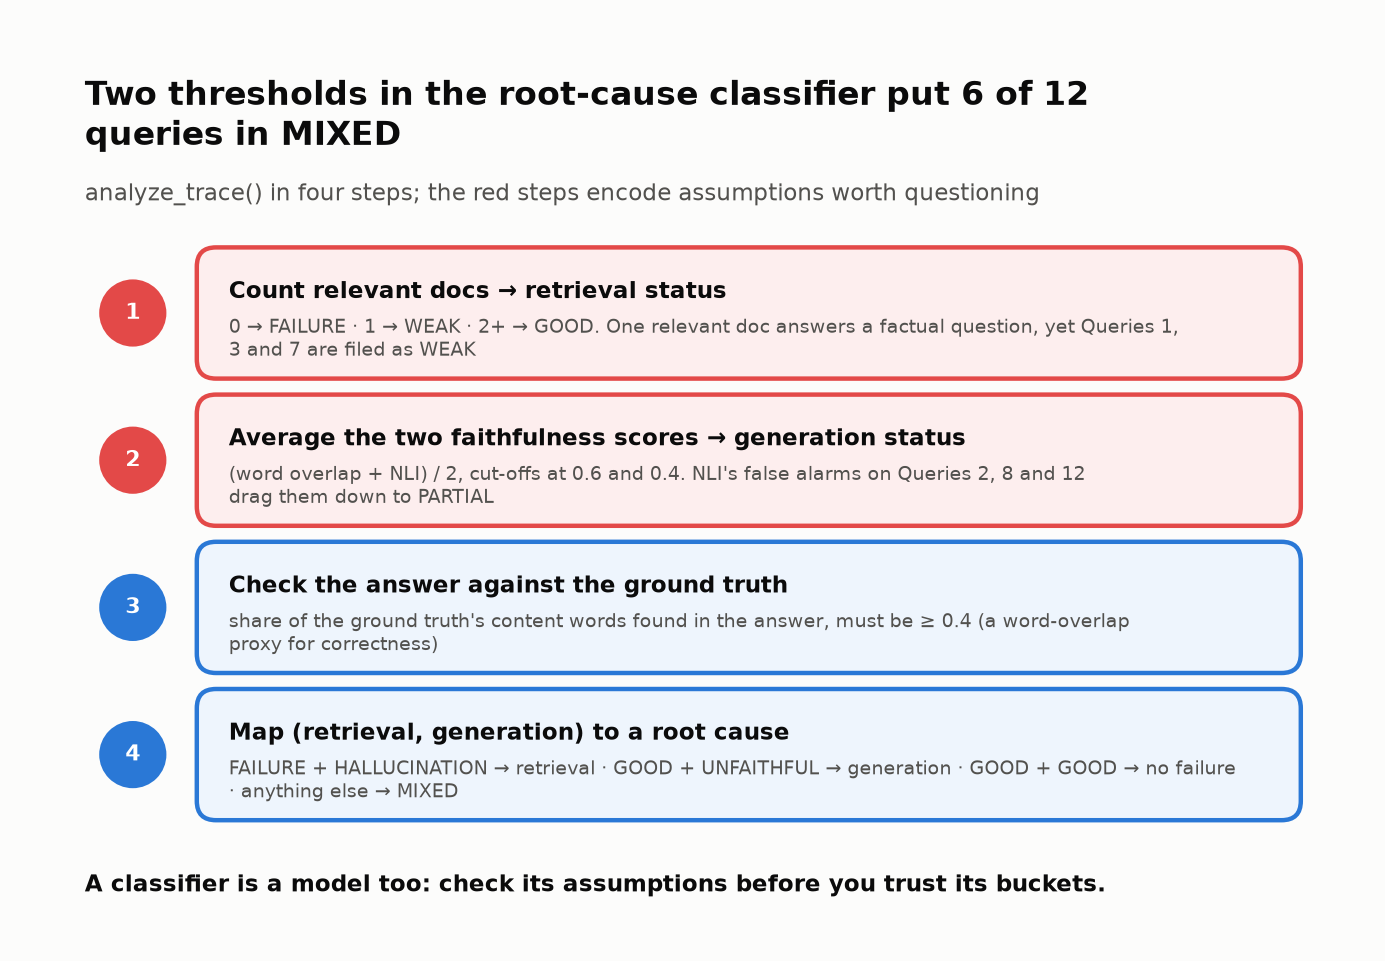
<sub>🖼️ *The red steps are assumptions, not measurements.*</sub>

🎛️ **Experiment:** retrieval counts as GOOD only with 2+ relevant docs. Drag `MIN_GOOD_DOCS` to **1** and run: what's left in MIXED?

In [ ]:
# 🎛️ Re-sort the 12 traces with a different "good retrieval" line (2 = the lab's rule)
MIN_GOOD_DOCS = 2  # @param {type:"slider", min:1, max:5, step:1}

buckets = defaultdict(list)
for t in traces:
    n_rel = sum(rag_dataset[t["id"] - 1]["relevance_labels"])
    ret = "❌ FAILURE" if n_rel == 0 else ("✅ GOOD" if n_rel >= MIN_GOOD_DOCS else "⚠️ WEAK")
    buckets[re.split(r" [—→]", root_cause(ret, t["generation_status"]))[0]].append(t["id"])
print(f"MIN_GOOD_DOCS = {MIN_GOOD_DOCS}:", dict(buckets))

🔍 **What just happened:** at 1, MIXED shrinks to [2, 8, 12], all three the scorer's doing. Two thresholds, not the pipeline, did the sorting.

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** MIXED [1, 2, 3, 7, 8, 12] · RETRIEVAL → HALLUCINATION [4, 6] · NO FAILURE [5, 9, 11] · GENERATION [10].
</details>

In [ ]:
# @title ❓ Quick check: Query 10: good retrieval, NLI 0.02, number flag 16. Where does the fix go?
answer = "— pick one —"  # @param ["— pick one —", "A) The retriever: embeddings or chunking", "B) Generation: the prompt, the model, or a guardrail that blocks unsupported numbers", "C) The index: remove stale docs"]
quiz("Where Query 10's fix goes", answer, correct="B",
     why="4 of 5 docs were relevant and said 12 weeks; the generator wrote 16. The earliest stage that went wrong owns the fix.",
     wrong={"A": 'Retrieval did its job: the right doc is ranked first.',
          "C": "That is Part 2's Query 13. Query 10's docs are current."})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>A root-cause classifier is a model too: check the grader before you blame the pipeline.</b></font>

</td></tr></table>

---

## 🔑 Part 1 in three lines

1. **Zero abstentions is a symptom.**
2. **Headline recall at your K;** check numbers with code.
3. **Every scorer has misses and false alarms**, root-cause classifiers included.

▶️ **Run:** your score on Part 1's exercises and checks, and what to revisit.

In [ ]:
scoreboard()

<center><font size="5"><b>➡️ Continue in Part 2: real employees start asking.</b></font></center>

<center>

[![Open Part 2 In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/04-rag-evaluation-part-2-lab.ipynb)

</center>

Part 2 rebuilds Part 1 in one hidden cell.